# Result Comparison Pipeline

This notebook compares existing craTEs of servql result directories.

## 0 · Setup

### ── 0.1 - Libraries and Scripts ──

In [65]:
# -- Libraries and helper functions -----------------------------------------
suppressPackageStartupMessages({
  library(ggplot2)
  if (requireNamespace("ggtext", quietly = TRUE)) {
    library(ggtext)
  }
})

find_project_dir <- function(start = getwd()) {
  current <- normalizePath(start, winslash = "/", mustWork = TRUE)
  repeat {
    if (file.exists(file.path(current, "scripts", "craTEs_own_function.R")) &&
        file.exists(file.path(current, "scripts", "comparison_f.R")) &&
        dir.exists(file.path(current, "R"))) {
      return(current)
    }
    parent <- dirname(current)
    if (identical(parent, current)) {
      stop("Could not find the craTEs project root from: ", start, call. = FALSE)
    }
    current <- parent
  }
}

project_dir <- find_project_dir()
setwd(project_dir)

source_project_file <- function(..., envir = .GlobalEnv) {
  path <- file.path(project_dir, ...)
  if (!file.exists(path)) {
    stop("Missing helper file: ", path, call. = FALSE)
  }
  source(path, local = envir)
}

source_project_file("scripts", "te_trend_classification_f.R")
source_project_file("scripts", "craTEs_own_function.R")
source_project_file("scripts", "comparison_csv_f.R")
source_project_file("scripts", "comparison_f.R")

[1] "sourcing the custom function from crates"


### ── 0.2 - Result Directory Specification ──


In [66]:
# ── User-editable comparison setup ────────────────────────
result_dirs <- c(
  "results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs",
  "results/results_E_Senescene_TE_Seq_raw_N_w_2.5e5_Hg38_craTEs"
)

# Optional narrowed analysis. Keep NULL to use the shared feature space.
target_tes <- NULL  # target_tes <- c("LTR5_Hs")
target_genes <- NULL # target_genes <- c("CST1", "GBP1")

# Global TE-subfamily analysis scope.
te_filter_mode <- "all"         # "all" or "significant"
te_significance_scope <- "any" # "any" = significant in at least one result, "all" = significant in every result
te_p_score_mode <- "mean_padj" # "mean_padj" or "mean_neg_log10_padj"
te_p_alpha <- 0.05

# Global TE ranking. Reuses the Section 7.1 ranking choices from TE_Seq_craTEs.ipynb.
te_global_top_k <- 10L
te_ranking_mode <- "activity_change" # "none" or "activity_change"
te_ranking_metric <- "sum_step_abs_delta"
te_ranking_aggregation <- "mean"     # "mean" or "max" across result directories
te_ranking_condition_order <- c("PRO", "ESEN", "LSEN")
te_contrast_top_k <- te_global_top_k
target_matrix_jaccard_threshold <- 0
target_matrix_jaccard_sign_sensitive <- TRUE
target_matrix_jaccard_include_zero_state <- TRUE
target_matrix_jaccard_levels <- c("te_subfamily", "gene", "gene_te_link")


### ── 0.3 - Load Stored Results TSVs ──


In [67]:
# ── Load selected result directories and show available TSVs ─
comparison_results <- load_comparison_results(result_dirs)
comparison_results <- store_matrix_plot_ids(comparison_results)
comparison_manifest <- print_result_manifest(comparison_results)

[INFO] Loading 2 result directories



[INFO] Loaded comparison result set



result,model fitactivity_fit_summary,sample fitsample_activity_diagnostics,lambda gridactivity_lambda_diagnostics,activity scoresactivity_scores,TE contrastste_contrast_summary,contrast fitsignif_model_diagnostics,target matrixtarget_gene_matrix_*,target summarytarget_summary,activity TEs,samples,fit rows,contrast TEs,target matrices
E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs,✓,✓n=12,✓n=100,✓,✓,✓n=3,✓n=3,✓,764,12,4,764,3
E_Senescene_TE_Seq_raw_N_w_2.5e5_Hg38_craTEs,✓,✓n=12,✗,✓,✓,✓n=3,✓n=3,✓,996,12,4,996,3


### ── 0.4 - Dataset Similarities ──

In [68]:
# ── Classify by shared/different E and N ──────────────────
comparison_class <- classify_comparison_set(comparison_results)
print_comparison_class(comparison_class)

result,E source,ref. genome,N mode,N source
E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs,Senescene TE Seq raw,Hg38,count,craTEs
E_Senescene_TE_Seq_raw_N_w_2.5e5_Hg38_craTEs,Senescene TE Seq raw,Hg38,weighted,craTEs


### ── 0.5 - Global TE Analysis Scope and Ranking ──

The TE frame is built once here and reused by the TE-level activity, contrast, and target-matrix sections.

| Level | Controlled by | Meaning |
|---|---|---|
| 1 - Shared feature space | `result_dirs` | Keep only TE subfamilies present in all selected result directories. |
| 2 - Optional scope filter | `target_tes`, `te_filter_mode` | Either keep all shared TEs, keep a manual list, or keep significant TEs from `te_contrast_summary.tsv`. |
| 3 - Global TE ranking | `te_ranking_mode`, `te_ranking_metric`, `te_global_top_k` | Optionally rank the remaining TEs by activity-change metrics and keep the global top-k. |
| 4 - Plot-specific view | section-specific thresholds and `top_k` | Correlation/Jaccard use the global TE frame; focused plots may still order or annotate that same frame by their own statistic. |

Significance filtering uses pairwise adjusted p-values: `te_significance_scope <- "any"` keeps TEs significant in at least one result directory, while `"all"` keeps only TEs significant in every result directory. With `te_p_score_mode <- "mean_padj"`, smaller values mean stronger adjusted-p evidence; `"mean_neg_log10_padj"` flips this to larger-is-stronger.

For ranked TE frames, `te_ranking_condition_order` defines the biological order of the activity means and `te_ranking_aggregation <- "mean"` or `"max"` combines each TE's ranking score across result directories.

The activity-change ranking options are inherited from `TE_Seq_craTEs.ipynb` Section 7.1:

| `te_ranking_metric` | Prioritises |
|---|---|
| `sum_step_abs_delta` | overall dynamics: `abs(ESEN - PRO) + abs(LSEN - ESEN)` |
| `max_step_abs_delta` | the strongest adjacent transition |
| `max_sum_abs_activity_score` | strongest absolute condition-wise activity signal |
| `abs_delta_ESEN_vs_PRO` / `PRO_ESEN` | the early-senescence gap only |
| `abs_delta_LSEN_vs_ESEN` / `ESEN_LSEN` | the late transition only |
| `abs_delta_LSEN_vs_PRO` / `PRO_LSEN` / `net_abs_delta` | the start-to-end gap only |
| `mean_activity_range` | the full condition mean range |
| `monotonic_step_abs_delta` | TEs changing in the same direction across adjacent steps |


In [69]:
# ── Build reusable TE analysis scope and optional global ranking ─
selected_te_space <- build_te_selection_space(
  comparison_results,
  target_tes = target_tes,
  filter_mode = te_filter_mode,
  significance_scope = te_significance_scope,
  p_score_mode = te_p_score_mode,
  alpha = te_p_alpha,
  comparison_class = comparison_class,
  ranking_mode = te_ranking_mode,
  ranking_metric = te_ranking_metric,
  ranking_top_k = te_global_top_k,
  ranking_aggregation = te_ranking_aggregation,
  ranking_condition_order = te_ranking_condition_order
)

if (identical(selected_te_space$status, "ok")) {
  print(selected_te_space$selection_summary, row.names = FALSE)

  # NULL keeps full shared-TE behavior; an explicit vector means the global TE frame was narrowed.
  analysis_tes <- if (identical(te_filter_mode, "all") &&
                       identical(te_ranking_mode, "none") &&
                       is.null(target_tes)) {
    NULL
  } else {
    selected_te_space$te_subfamilies
  }

  te_activity_ranking_summary <- selected_te_space$activity_ranking
  if (is.list(te_activity_ranking_summary) && identical(te_activity_ranking_summary$status, "ok")) {
    te_activity_ranking_display <- te_activity_ranking_summary$selected_te_summary
    ranking_display_cols <- intersect(
      c("rank", "te_subfamily", "global_ranking_score", "mean_result_ranking_score", "max_result_ranking_score", "result_score_range", "n_results"),
      colnames(te_activity_ranking_display)
    )
    te_activity_ranking_display <- te_activity_ranking_display[, ranking_display_cols, drop = FALSE]
    numeric_cols <- vapply(te_activity_ranking_display, is.numeric, logical(1))
    te_activity_ranking_display[numeric_cols] <- lapply(te_activity_ranking_display[numeric_cols], round, digits = 4)
    print(te_activity_ranking_display, row.names = FALSE)
  }
} else {
  message(selected_te_space$reason)
  analysis_tes <- character()
}


 filter_mode significance_scope p_score_mode alpha    ranking_mode
         all           not used    mean_padj  0.05 activity_change
     ranking_metric ranking_aggregation ranking_top_k n_shared_activity_tes
 sum_step_abs_delta                mean            10                   764
 n_selected_tes
             10
                                                                                                                                                        note
 All shared TE subfamilies are retained. Then globally ranked by sum of adjacent mean activity changes (mean across result directories) and top 10 retained.
 rank    te_subfamily global_ranking_score mean_result_ranking_score
    1     HERV4_I-int               0.1604                    0.1604
    2          MER61B               0.1322                    0.1322
    3       MamRep488               0.1188                    0.1188
    4          LTR88c               0.1121                    0.1121
    5          LTR88a  

## 1 · Shared feature space analysis

Overlap tables are stored first, then rendered as fixed-layout Venn diagrams with absolute counts in the diagram and relative summaries below.

In [70]:
# ── Build stored shared feature-space tables ─────────────
shared_feature_space <- build_shared_feature_space(
  comparison_results,
  comparison_class = comparison_class
)

shared_feature_overview <- display_shared_feature_overview(shared_feature_space)
shared_feature_absolute_counts <- shared_feature_space$absolute_counts
shared_feature_relative_counts <- shared_feature_space$relative_counts

category,attribute,source,status,union,shared by all,dataset totals,interpretation
Samples,activity-score columns,activity_scores.tsv,ok,12,12,100kb count n=12; 250kb weighted n=12,Same E: sample overlap is mainly a sanity check.
Gene IDs,target-gene row IDs,"target_gene_matrix_*.tsv (ESEN_vs_PRO, LSEN_vs_ESEN, LSEN_vs_PRO)",ok,14989,14690,100kb count n=14690; 250kb weighted n=14989,"Same E, different N: useful for target-support stability."
TE subfamilies,activity-score TE rows,activity_scores.tsv,ok,996,764,100kb count n=764; 250kb weighted n=996,Different N: shared TEs define the comparable activity rows.
Significant genes,not analysed,skipped,skipped,NA,NA,not analysed,Skipped: no dedicated significant-gene source is defined.


### ── 1.1 - Samples ──


dataset,shared of dataset,shared of union,only here of dataset,only here of union
100kb count,100.0%,100.0%,0.0%,0.0%
250kb weighted,100.0%,100.0%,0.0%,0.0%


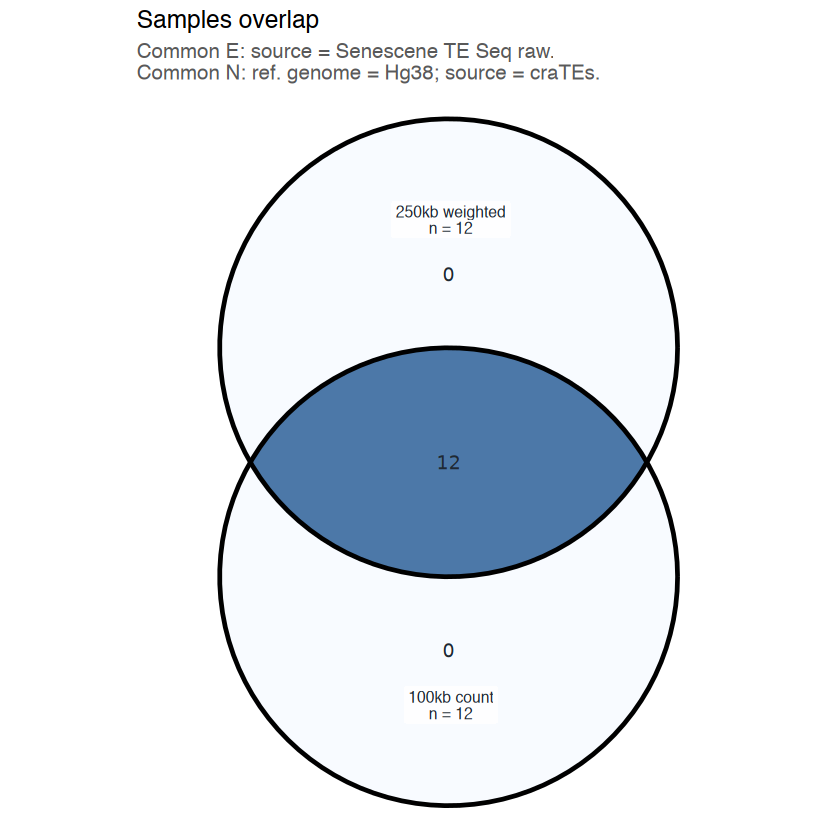

In [71]:
# ── Sample overlap Venn and relative table ───────────────
sample_overlap_plot <- plot_shared_feature_venn(shared_feature_space, "samples")
if (!is.null(sample_overlap_plot)) {
  print(sample_overlap_plot)
}
sample_overlap_table <- display_shared_feature_relative_table(shared_feature_space, "samples")

### ── 1.2 - Gene IDs ──


dataset,shared of dataset,shared of union,only here of dataset,only here of union
100kb count,100.0%,98.0%,0.0%,0.0%
250kb weighted,98.0%,98.0%,2.0%,2.0%


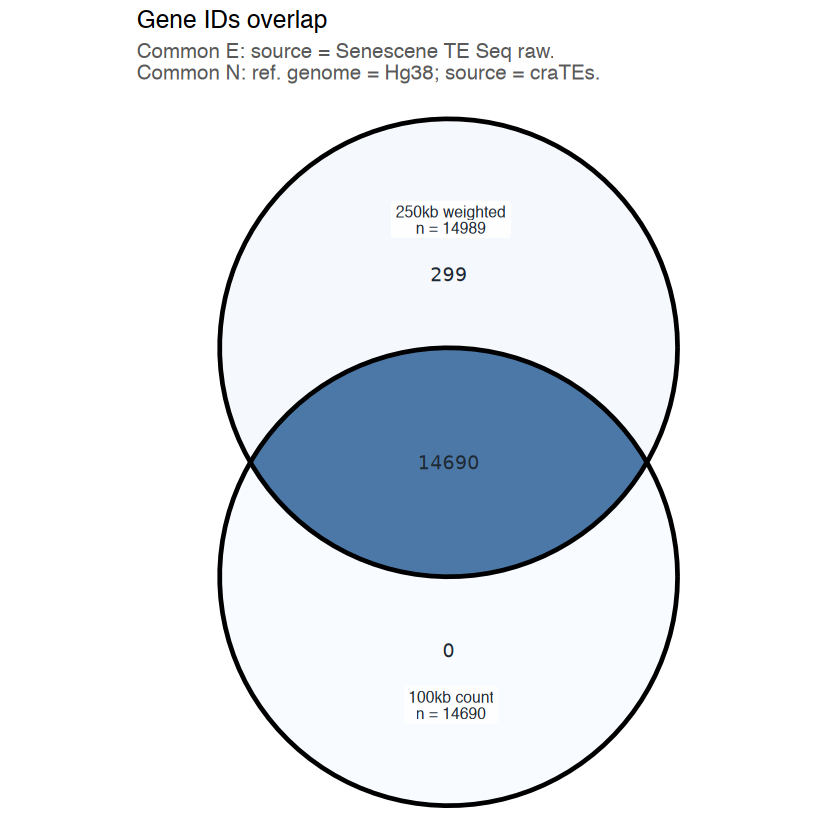

In [72]:
# ── Target gene-ID overlap Venn and relative table ───────
gene_overlap_plot <- plot_shared_feature_venn(shared_feature_space, "gene_ids")
if (!is.null(gene_overlap_plot)) {
  print(gene_overlap_plot)
}
gene_overlap_table <- display_shared_feature_relative_table(shared_feature_space, "gene_ids")

### ── 1.3 - TE Subfamilies ──


dataset,shared of dataset,shared of union,only here of dataset,only here of union
100kb count,100.0%,76.7%,0.0%,0.0%
250kb weighted,76.7%,76.7%,23.3%,23.3%


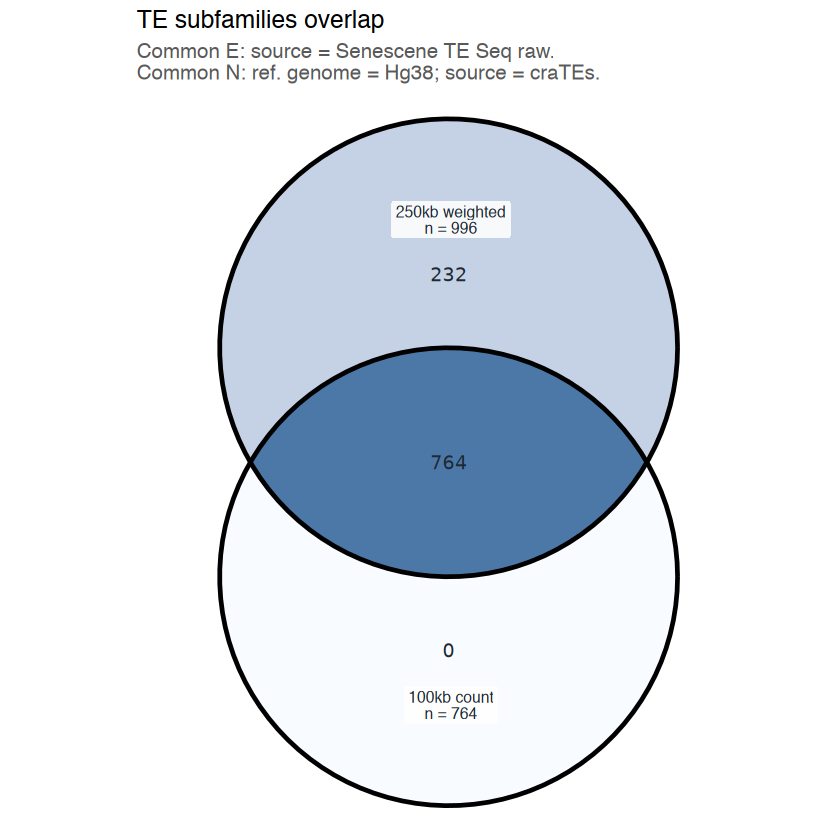

In [73]:
# ── TE-subfamily overlap Venn and relative table ─────────
te_overlap_plot <- plot_shared_feature_venn(shared_feature_space, "te_subfamilies")
if (!is.null(te_overlap_plot)) {
  print(te_overlap_plot)
}
te_overlap_table <- display_shared_feature_relative_table(shared_feature_space, "te_subfamilies")

### ── 1.4 - Significant Genes ──

Skipped until a dedicated significant-gene source is defined.

In [74]:
# ── Significant genes are intentionally not inferred here ─
significant_gene_overlap_note <- display_shared_feature_skip_note(
  shared_feature_space,
  "significant_genes"
)

category,status,source,interpretation
Significant genes,skipped,skipped,Skipped: no dedicated significant-gene source is defined.


## 2 · Model fit comparison

`activity_fit_summary.tsv` is shown as overall model fit, with condition-wise rows nested inside the overall bar when the upstream dataset similarity makes that comparison meaningful.

In [75]:
# ── Prepare model-fit plots from activity_fit_summary.tsv ─
activity_fit_plots <- plot_activity_fit_comparison(
  comparison_results,
  comparison_class = comparison_class
)


### ── 2.1 - Mean R2 ──

Overall bars show total model fit per result directory; transparent condition bars are shown inside when condition-level comparison is valid.

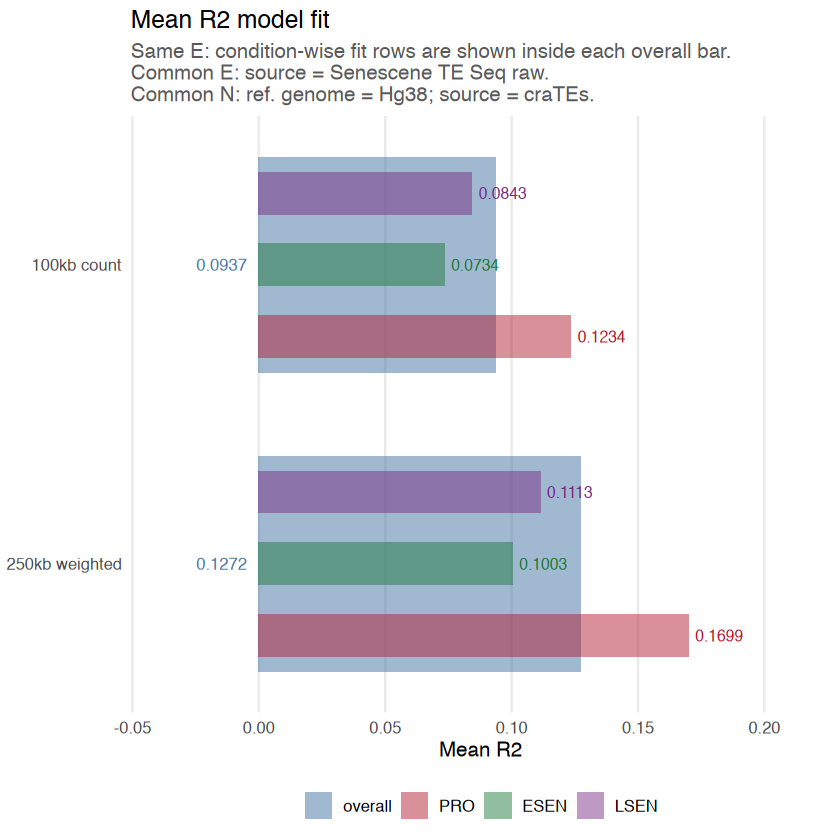

In [76]:
# ── Mean R2 model-fit plot ───────────────────────────────
if (!is.null(activity_fit_plots$mean_r2)) {
  print(activity_fit_plots$mean_r2)
}


### ── 2.2 - Mean R2 Ratio ──

The ratio view uses the same overall and condition-wise layout, making relative fit differences easier to compare.


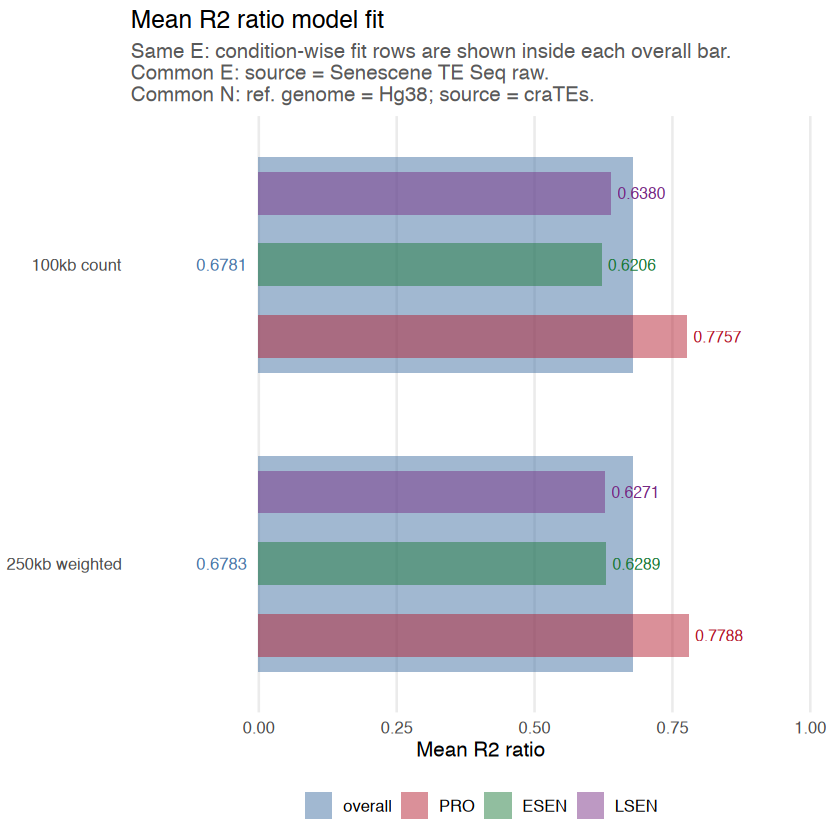

In [77]:
# ── Mean R2 ratio model-fit plot ─────────────────────────
if (!is.null(activity_fit_plots$mean_r2_ratio)) {
  print(activity_fit_plots$mean_r2_ratio)
}


### ── 2.3 - Lambda Best ──

`lambda_best` describes the sample-specific regularisation selected by cross-validation. The plot shows those per-sample values from `sample_activity_diagnostics.tsv` and overlays the global lambda selected across samples when `activity_lambda_diagnostics.tsv` is available. Similar fit with lower or more stable lambdas can indicate a more robust result, while large differences suggest that the compared matrices require different levels of shrinkage.


                                            result_id n_values
   results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs       12
 results_E_Senescene_TE_Seq_raw_N_w_2.5e5_Hg38_craTEs       12
 median_lambda_best min_lambda_best max_lambda_best global_lambda_min
         0.08510777      0.07065797      0.12347680        0.09340567
         0.06602433      0.05481456      0.08728028                NA


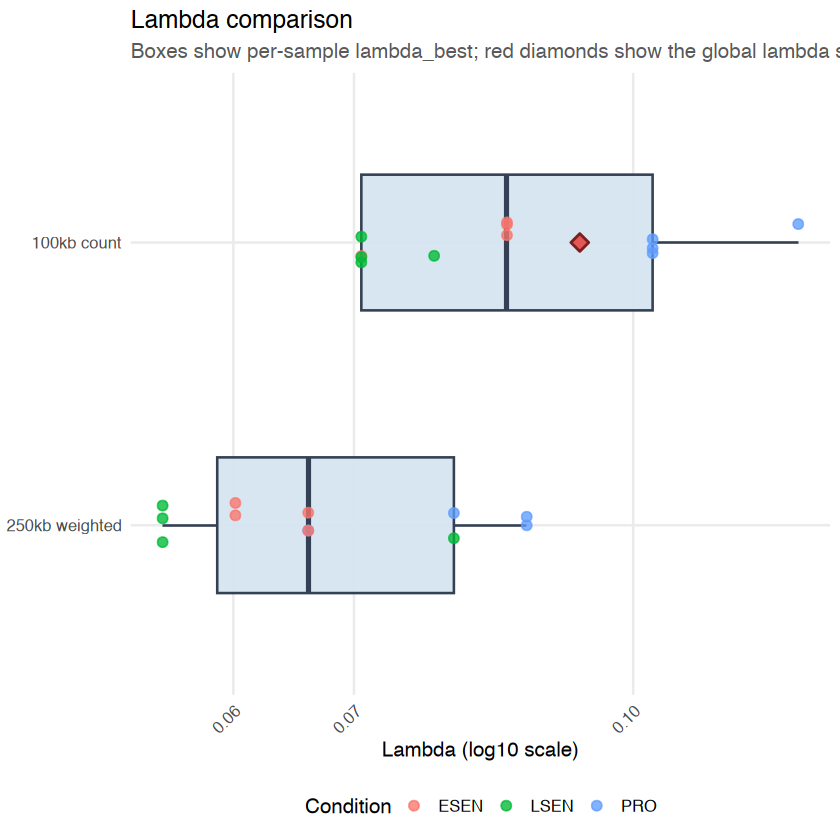

In [78]:
# ── Lambda-best and global-lambda plot ─────────────────────
lambda_best_summary <- summarise_lambda_best(comparison_results)
lambda_display_cols <- intersect(
  c("result_id", "n_values", "median_lambda_best", "min_lambda_best", "max_lambda_best", "global_lambda_min"),
  colnames(lambda_best_summary))
print(lambda_best_summary[, lambda_display_cols, drop = FALSE], row.names = FALSE)

lambda_best_plot <- plot_lambda_best_comparison(comparison_results, comparison_class = comparison_class)
if (!is.null(lambda_best_plot)) {
  print(lambda_best_plot)}

## 3 · Activity score comparison

`activity_scores.tsv` is compared on the global TE frame from Section 0.5 and on the shared samples or condition means available across all selected result directories. With the current default this frame is the globally ranked top `te_global_top_k` TE subfamilies; set `te_ranking_mode <- "none"` to return to all shared TEs.


> **Correlation**: overall similarity inside the global TE frame
> **Cross-result signal**: strongest absolute activity pattern across result directories
> **Top change**: activity magnitude and cross-result shifts inside the same frame
> **Jaccard**: overlap of active/non-zero signals after the global TE selection
> **Heatmap**: qualitative sign and sample-pattern inspection for the selected TE frame
> **Fixed contrast**: contrast-specific evidence, also constrained by the global TE frame

In [79]:
# ── Activity-score comparison variables ─────────────────
# These top-k values default to the global TE frame from Section 0.5.
activity_heatmap_top_k <- te_global_top_k
activity_abs_signal_top_k <- min(12L, te_global_top_k)
activity_top_change_k <- te_global_top_k
activity_contrast_change_contrasts <- NULL  # NULL = all shared contrasts
activity_contrast_change_top_k <- activity_top_change_k
activity_contrast_focus_contrasts <- NULL  # NULL = all shared pairwise contrasts
activity_contrast_focus_top_k <- min(12L, te_global_top_k)
activity_contrast_focus_alpha <- te_p_alpha
activity_jaccard_threshold <- 0
activity_jaccard_level <- "auto"  # "auto", "cell" = TE-sample pairs, "te_subfamily" = active TE sets

activity_score_summary <- summarise_activity_scores(
  comparison_results,
  target_tes = analysis_tes
)


### ── 3.1 - Activity Score Similarity ──

The correlation plot gives a global similarity view over the shared activity-score profile for a shared TE subfamily and sample space. 

Note that sparse activity profiles, forced by the penelised linear Regression can inflate the correlation. 

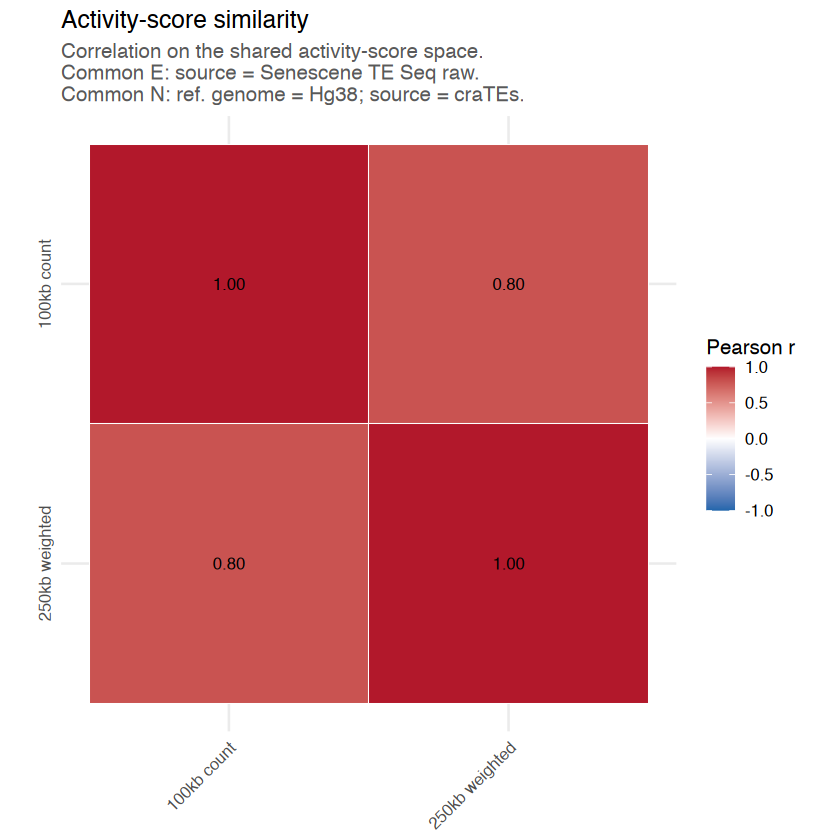

In [80]:
# ── Activity-score correlation plot ─────────────────────
source_project_file("scripts", "comparison_f.R")

if (identical(activity_score_summary$status, "ok")) {
  print(plot_activity_score_similarity(
    comparison_results,
    target_tes = analysis_tes,
    comparison_class = comparison_class
  ))
} else {
  message(activity_score_summary$reason)
}


### ── 3.1.b - Cross-Sample Activity Score Similarity ──

This half-matrix compares every sample activity profile from one result directory against every sample activity profile from the other result directory.
It only runs for exactly two selected result directories. Green frames mark sample pairs from the same condition; orange frames mark the exact same sample.

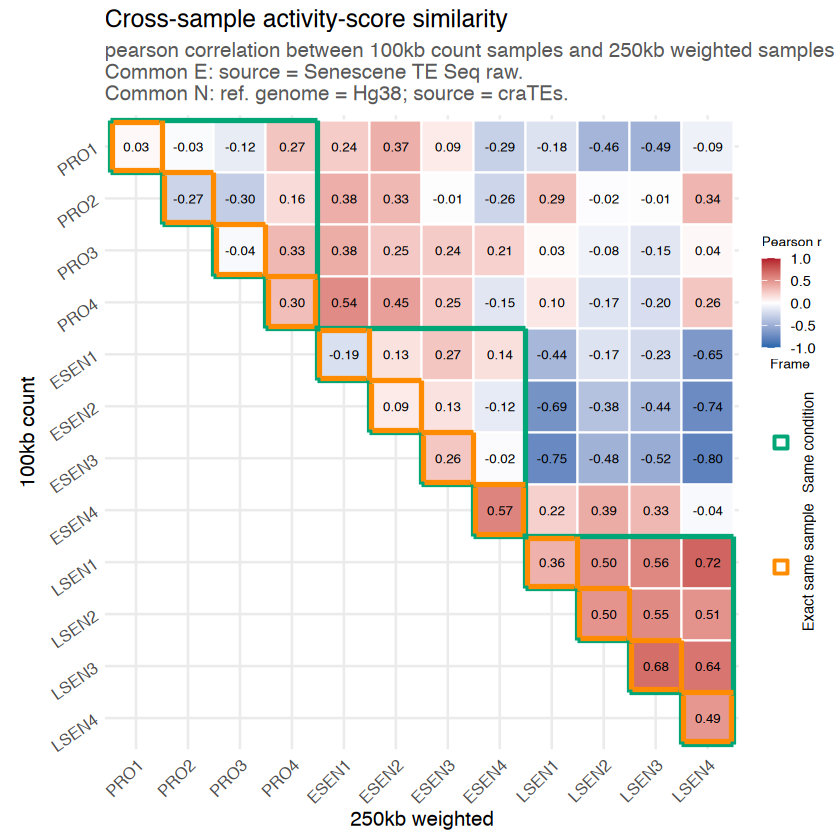

In [81]:
# ── Cross-sample activity-score similarity ──────────────
# Uses stored activity_scores.tsv objects; does not rerun getActivities().
source_project_file("scripts", "comparison_f.R")

activity_cross_sample_similarity <- summarise_activity_cross_sample_similarity(
  comparison_results,
  target_tes = analysis_tes,
  method = "pearson",
  comparison_class = comparison_class
)

if (identical(activity_cross_sample_similarity$status, "ok")) {
  activity_cross_sample_similarity_plot <- plot_activity_cross_sample_similarity(
    activity_cross_sample_similarity,
    triangle = "upper"
  )
  activity_cross_sample_similarity_plot
} else {
  message(activity_cross_sample_similarity$reason)
}


### ── 3.1.c - Cross-Result Absolute Activity Signal ──

This panel uses the same visual grammar as the TE-Seq Section 7.1b plot, but each result directory first contributes one condition mean per TE subfamily. The ranking score is:

$$
R_t^{(D)} = \max_{c \in \{PRO, ESEN, LSEN\}} \sum_{d \in D} \left| \bar A_{t,c,d} \right|
$$

with $\bar A_{t,c,d}$ as the mean inferred activity score of TE subfamily $t$ in condition $c$ for result directory $d$. Brackets show the min-to-max range across result directories; dots show the cross-result condition mean.

In [82]:
# -- Ranking: cross-result absolute activity signal ----------------------------
source_project_file("scripts", "comparison_f.R")

activity_abs_signal_summary <- summarise_cross_result_absolute_activity_signal(
  comparison_results,
  target_tes = analysis_tes,
  top_k = activity_abs_signal_top_k,
  condition_order = te_ranking_condition_order,
  comparison_class = comparison_class
)

if (identical(activity_abs_signal_summary$status, "ok")) {
  activity_abs_signal_ranking_display_cols <- intersect(
    c(
      "rank",
      "te_subfamily",
      "ranking_score",
      paste0("mean_activity_", activity_abs_signal_summary$condition_order),
      paste0("sum_abs_activity_", activity_abs_signal_summary$condition_order)
    ),
    colnames(activity_abs_signal_summary$selected_te_summary)
  )
  activity_abs_signal_ranking_display <- activity_abs_signal_summary$selected_te_summary[, activity_abs_signal_ranking_display_cols, drop = FALSE]
  numeric_cols <- vapply(activity_abs_signal_ranking_display, is.numeric, logical(1))
  activity_abs_signal_ranking_display[numeric_cols] <- lapply(activity_abs_signal_ranking_display[numeric_cols], round, digits = 4)

  activity_abs_signal_ranking_display
} else {
  message(activity_abs_signal_summary$reason)
}


rank,te_subfamily,ranking_score,sum_abs_activity_PRO,sum_abs_activity_ESEN,sum_abs_activity_LSEN
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,MER61B,0.1424,0.1424,0.0721,0.0223
2,HERV4_I-int,0.1405,0.1405,0.0913,0.0022
3,MamRep488,0.1128,0.1128,0.0650,0.0050
4,Helitron2Na_Mam,0.1058,0.1058,0.0328,0.0094
5,MamGypsy2-LTR,0.1034,0.1034,0.0075,0.0683
6,LTR88a,0.1029,0.1029,0.0535,0.0119
7,UCON55,0.0968,0.0968,0.0357,0.0155
8,THE1B-int,0.0844,0.0844,0.0517,0.0191
9,LTR88c,0.0796,0.0796,0.0728,0.0009


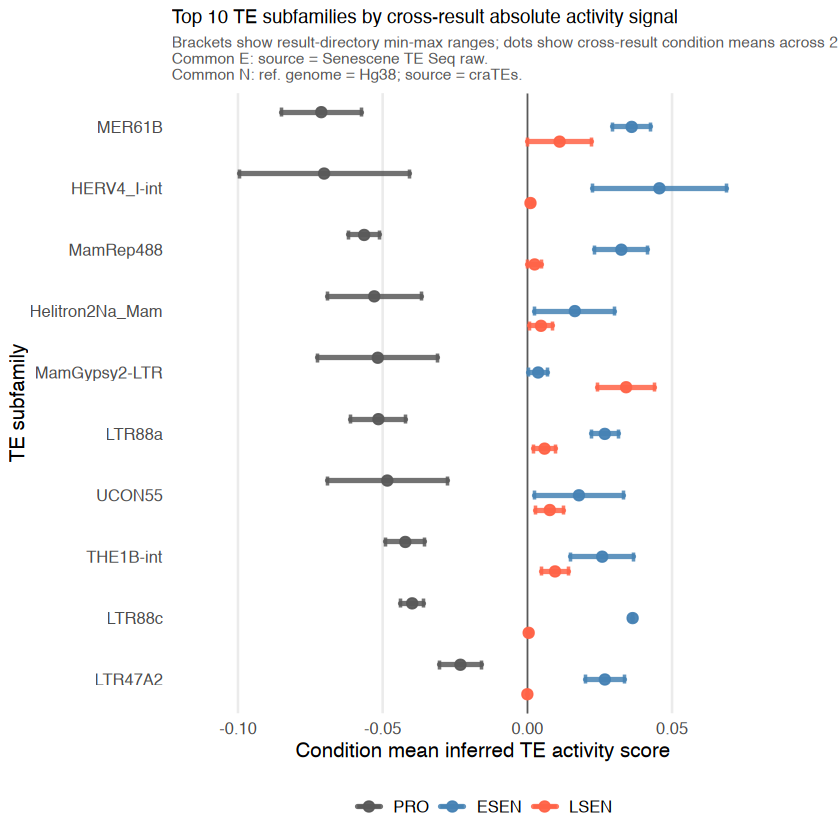

In [83]:
# -- Plot: render the cross-result activity-signal ranking ---------------------
source_project_file("scripts", "comparison_f.R")

if (!exists("activity_abs_signal_summary", inherits = TRUE)) {
  if (!exists("analysis_tes", inherits = TRUE)) {
    analysis_tes <- NULL
  }
  if (!exists("activity_abs_signal_top_k", inherits = TRUE)) {
    activity_abs_signal_top_k <- if (exists("te_global_top_k", inherits = TRUE)) min(12L, te_global_top_k) else 12L
  }
  if (!exists("te_ranking_condition_order", inherits = TRUE)) {
    te_ranking_condition_order <- NULL
  }
  if (!exists("comparison_class", inherits = TRUE)) {
    comparison_class <- classify_comparison_set(comparison_results)
  }
  activity_abs_signal_summary <- summarise_cross_result_absolute_activity_signal(
    comparison_results,
    target_tes = analysis_tes,
    top_k = activity_abs_signal_top_k,
    condition_order = te_ranking_condition_order,
    comparison_class = comparison_class
  )
}

activity_abs_signal_plot <- plot_cross_result_absolute_activity_signal_summary(
  activity_abs_signal_summary
)

if (inherits(activity_abs_signal_plot, "ggplot")) {
  print(activity_abs_signal_plot)
}


### ── 3.2 - Top Activity: Mag. + Change ──

> Which TE-subfamilies have the strongest changes in their cis-regulatory activty passing to different cell states across changing in experiments? 

Top-k uses max mean abs(activity) across conditions within one result dir; right labels show max delta per TE.

> among the strongest activity signals, which TE subfamilies stay stable across result directories and which ones change most?

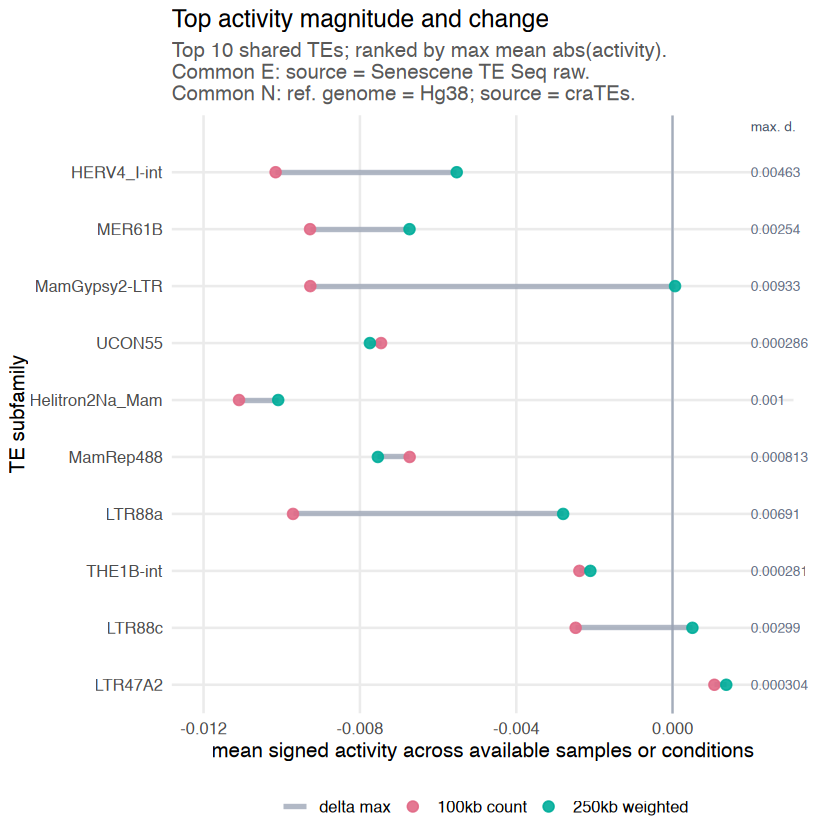

In [84]:
# ── Top activities and cross-result change ──────────────
source_project_file("scripts", "comparison_f.R")

activity_top_change_plot <- plot_activity_top_change(
  comparison_results,
  target_tes = analysis_tes,
  top_k = activity_top_change_k,
  use_abs = FALSE,
  comparison_class = comparison_class
)
if (inherits(activity_top_change_plot, "ggplot")) {
  print(activity_top_change_plot)
}


### ── 3.2.b - Contrast-Specific Change ──

Same layout as 3.2, but using `delta_<contrast>` from `te_contrast_summary.tsv`. One plot is printed per contrast.

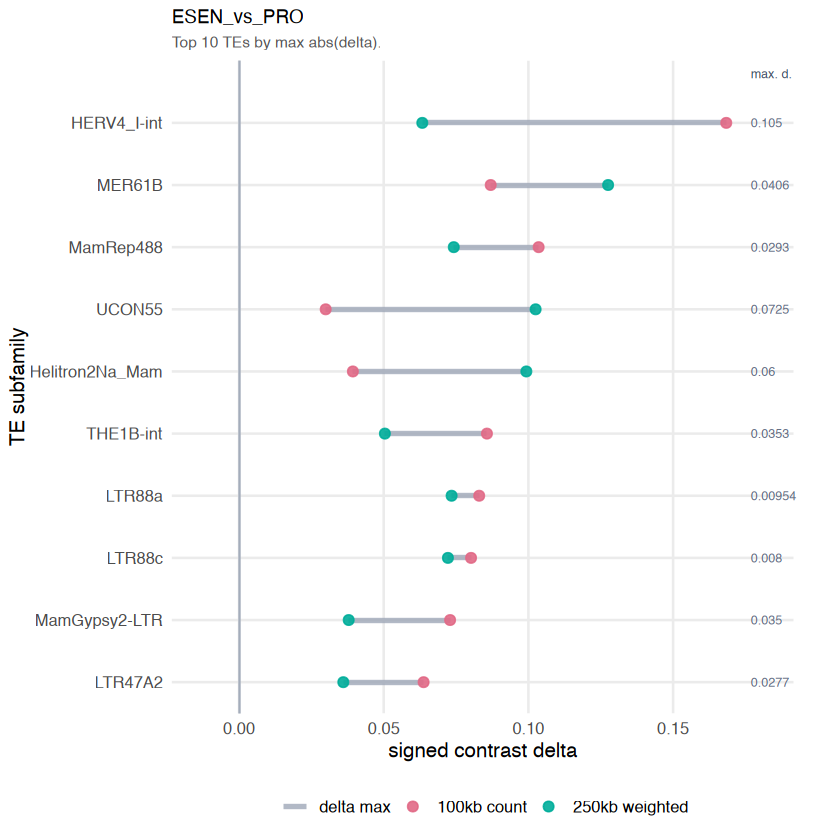

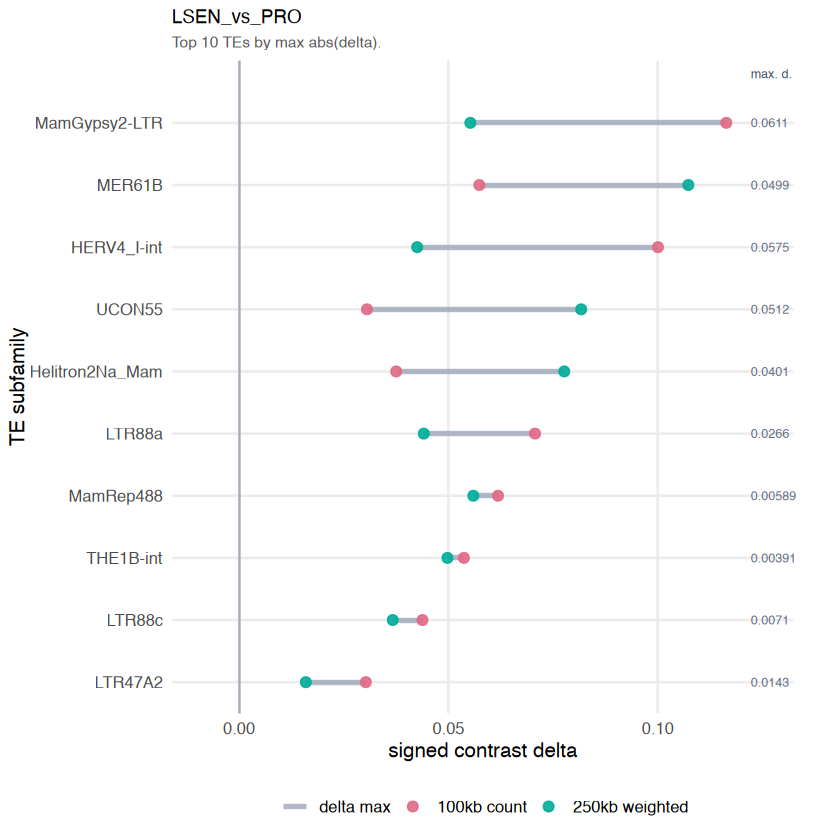

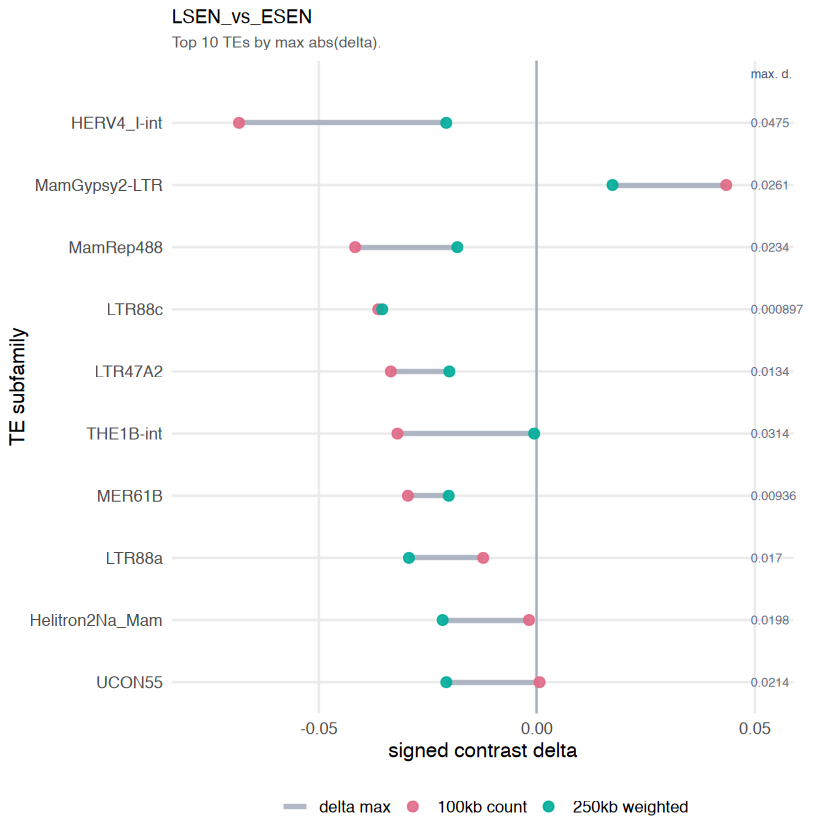

In [85]:
# ── Contrast-specific TE delta change plots ──────────────
source_project_file("scripts", "comparison_f.R")

if (!exists("comparison_class", inherits = TRUE)) {
  comparison_class <- classify_comparison_set(comparison_results)
}
if (!exists("analysis_tes", inherits = TRUE)) {
  analysis_tes <- NULL
}
if (!exists("activity_contrast_change_contrasts", inherits = TRUE)) {
  activity_contrast_change_contrasts <- NULL
}
if (!exists("activity_contrast_change_top_k", inherits = TRUE)) {
  activity_contrast_change_top_k <- if (exists("activity_top_change_k", inherits = TRUE)) activity_top_change_k else 30L
}
activity_contrast_change_summary <- summarise_activity_contrast_change(
  comparison_results,
  contrasts = activity_contrast_change_contrasts,
  target_tes = analysis_tes,
  top_k = activity_contrast_change_top_k,
  comparison_class = comparison_class
)

if (identical(activity_contrast_change_summary$status, "ok")) {
  activity_contrast_change_plots <- print_activity_contrast_change_plots(
    activity_contrast_change_summary
  )
} else {
  message(activity_contrast_change_summary$reason)
}


### ── 3.3 - Active Signal Jaccard Overlap ──

First, we only compare activity scores of TE subfamilies, where `abs(activity_score) > activity_jaccard_threshold` to compare them after. 
Therefore negative activity scores count as active when their absolute value exceeds the threshold.

When `activity_jaccard_level = auto`: Lets the notebook choose. if shared activity-score columns exist, it uses `cell` else `te_subfamily`

When `activity_jaccard_level = cell`: Do the same TE subfamilies become active in the same samples/conditions? Compares active TE-sample entries

When `activity_jaccard_level = te_subfamily`: Do the result dirs identify the same TE subfamilies as active at least somewhere? Compares only active TE names, ignoring where they are active.

Jaccard overlap compares active activity-score signals as sets: `intersection / union`.
This is useful next to correlation because it is less dominated by shared zero entries.

So the interpretation is:
high Jaccard: the same activity signals are active in both result dirs
low Jaccard: activity is present in different TEs or different sample positions
correlation high but Jaccard low: many shared zeros or similar global structure, but active signals differ
correlation moderate but Jaccard high: active signal locations agree, but activity magnitudes differ

In [86]:
# ── Jaccard overlap parameters ─────────────────────────
activity_jaccard_summary <- summarise_activity_jaccard(
  comparison_results,
  target_tes = analysis_tes,
  threshold = activity_jaccard_threshold,
  level = activity_jaccard_level,
  comparison_class = comparison_class
)

if (identical(activity_jaccard_summary$status, "ok")) {
  cat("activity_jaccard_level:", activity_jaccard_level,
      "->", activity_jaccard_summary$level,
      "(auto uses TE-sample cells when shared columns exist; otherwise TE-subfamily sets)
")
  cat("activity_jaccard_threshold:", activity_jaccard_threshold,
      "(active means abs(activity_score) > threshold)
")
  cat("analysis_tes:",
      if (is.null(analysis_tes)) "all shared TE subfamilies" else paste(length(analysis_tes), "selected TE subfamilies"),
      "
")
} else {
  message(activity_jaccard_summary$reason)
}


activity_jaccard_level: auto -> cell (auto uses TE-sample cells when shared columns exist; otherwise TE-subfamily sets)
activity_jaccard_threshold: 0 (active means abs(activity_score) > threshold)
analysis_tes: 10 selected TE subfamilies 


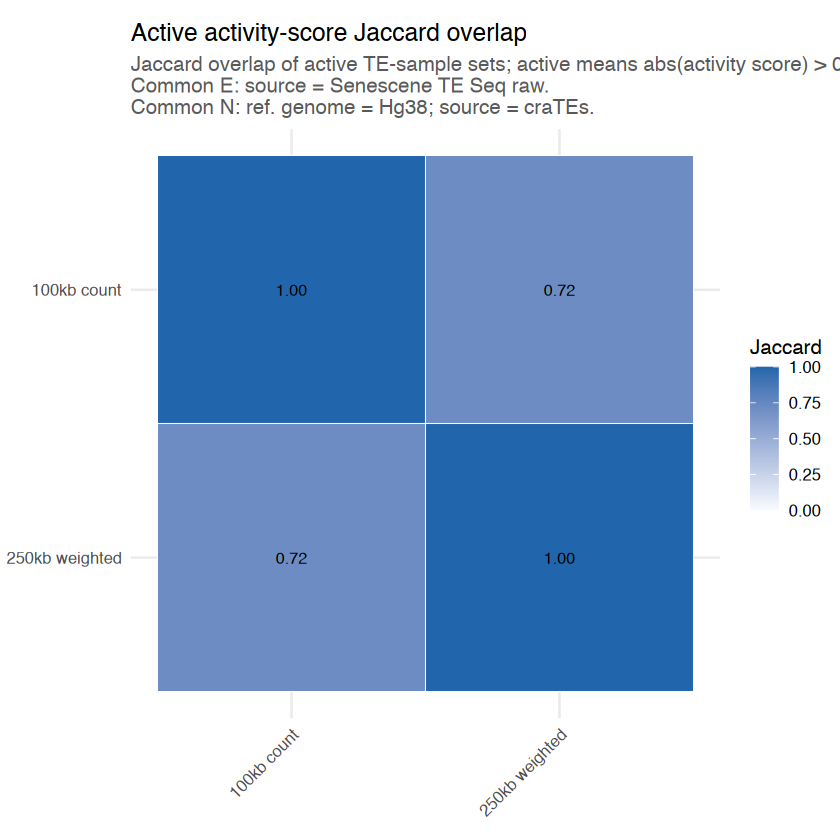

In [87]:
# ── Active activity-score Jaccard overlap ───────────────
activity_jaccard_plot <- plot_activity_jaccard(
  comparison_results,
  target_tes = analysis_tes,
  threshold = activity_jaccard_threshold,
  level = activity_jaccard_level,
  comparison_class = comparison_class
)
if (inherits(activity_jaccard_plot, "ggplot")) {
  print(activity_jaccard_plot)
}

aktive TEs count:    543
aktive TEs weighted: 617
aktive TEs in both: 468
TE-level Jaccard:    0.676

### ── 3.4 - Activity Score Heatmap ──

This heatmap is a qualitative view of sign and sample-pattern agreement inside the global TE frame from Section 0.5. If `te_ranking_mode <- "activity_change"`, the displayed rows come from the selected activity-change ranking; if ranking is off, `activity_heatmap_top_k` falls back to the strongest summed absolute activity rows.

When the TE frame is explicit, for example manual, significant, or globally ranked, rows are grouped by majority `trend_class` from `te_contrast_summary.tsv` when available. Within each class, the heatmap orders TEs by displayed activity magnitude so the strongest visible patterns stay near the top.


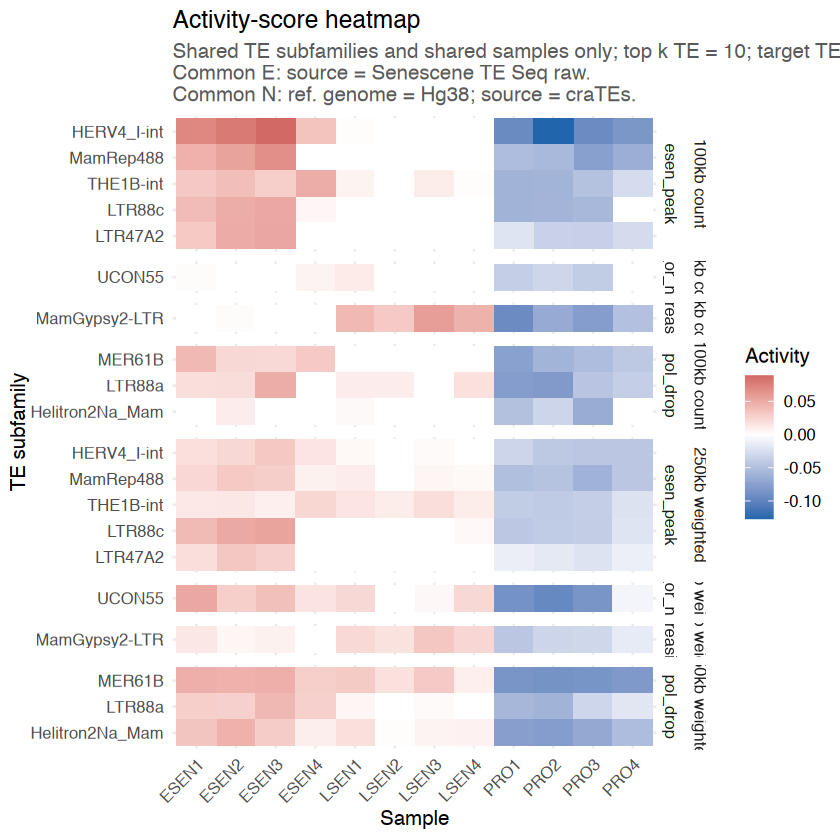

In [88]:
# ── Activity-score heatmap ──────────────────────────────
if (identical(activity_score_summary$status, "ok")) {
  print(plot_activity_score_heatmap(
    comparison_results,
    target_tes = analysis_tes,
    max_tes = activity_heatmap_top_k,
    comparison_class = comparison_class
  ))
} else {
  message(activity_score_summary$reason)
}


### ── 3.5 - Activity Score Sparsity ──

`mean_sparsity_percent` summarizes how sparse the fitted activity scores are, using the same overall and condition-wise layout as model fit.

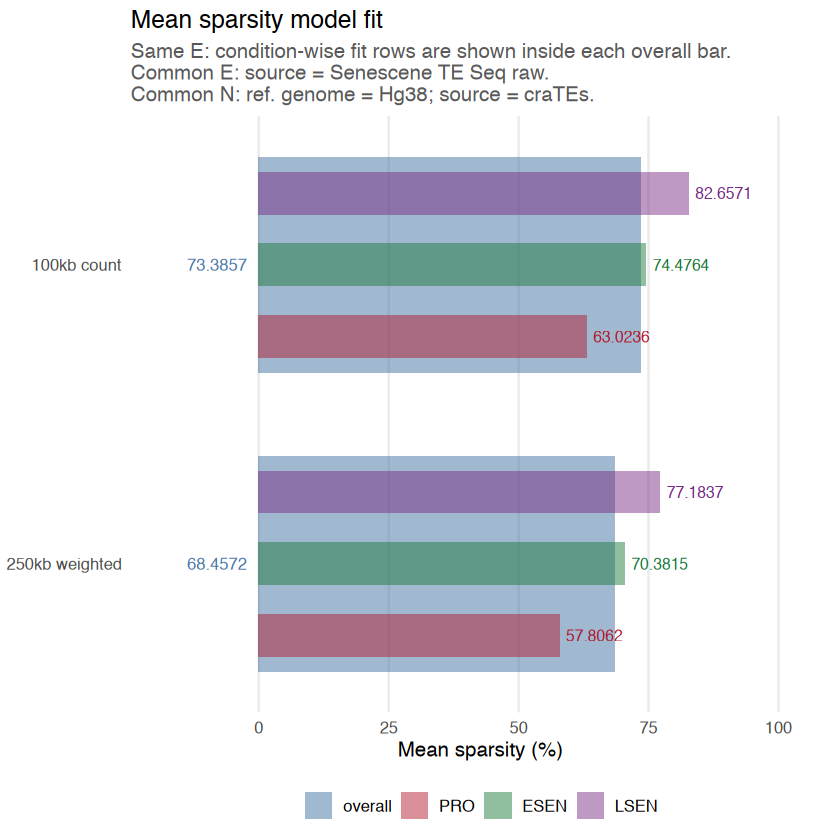

In [89]:
# ── Mean sparsity plot ───────────────────────────────────
sparsity_plot <- plot_sparsity_comparison(
  comparison_results,
  comparison_class = comparison_class
)
if (!is.null(sparsity_plot)) {
  print(sparsity_plot)
}


## 4 · TE contrast comparison

`te_contrast_summary.tsv` is used here to compare whether result directories lead to similar TE-level biological conclusions. This section uses the global TE frame from Section 0.5 first, then ranks or annotates those TEs by contrast evidence where a plot needs a focused order. It does not re-run significance testing; `*_signif_act.tsv` is only loaded where needed to recover raw pairwise p-values for the aggregated evidence labels.

### ── 4.0 - Contrast Model-Fit Diagnostics ──

`signif_model_diagnostics.tsv` stores one model-level diagnostic row per pairwise contrast from `getSignifActivities()`. This plot compares those fitted contrast models across result directories before interpreting the TE-level contrast evidence.

                                            result_id r_squared      rss
   results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs    0.1144 98970.91
 results_E_Senescene_TE_Seq_raw_N_w_2.5e5_Hg38_craTEs    0.1576 94710.39
 f_statistic n_aliased
      9.9582         0
     11.3592         0


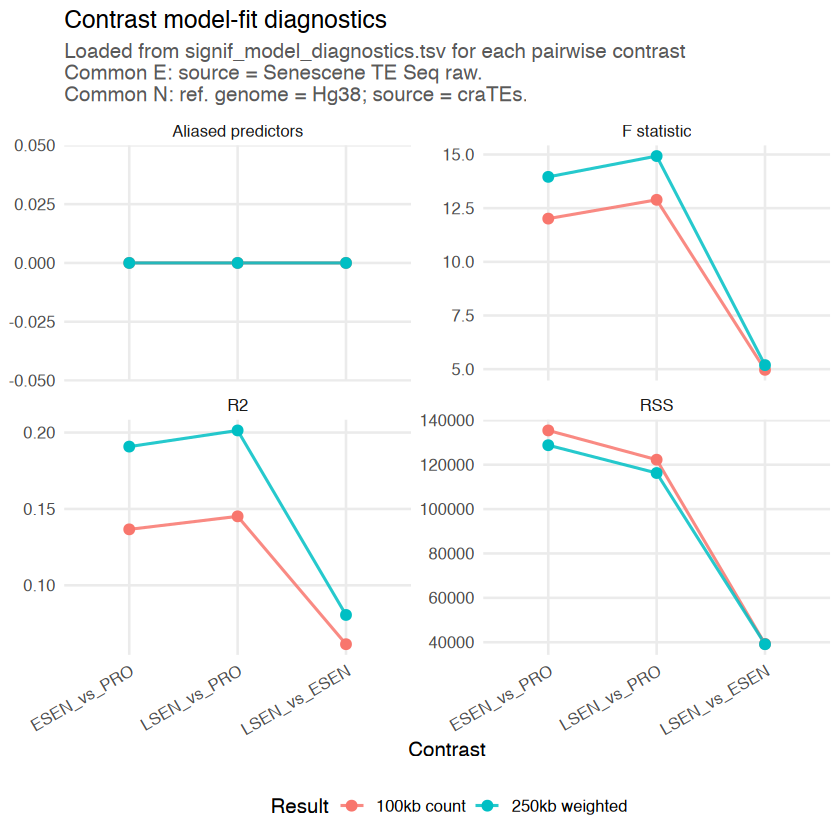

In [90]:
# ── Contrast model-fit diagnostics ─────────────────────
contrast_fit_diagnostics <- summarise_signif_model_diagnostics(comparison_results)
if (identical(contrast_fit_diagnostics$status, "ok")) {
  contrast_fit_display <- contrast_fit_diagnostics$summary_table
  numeric_cols <- vapply(contrast_fit_display, is.numeric, logical(1))
  contrast_fit_display[numeric_cols] <- lapply(contrast_fit_display[numeric_cols], round, digits = 4)
  print(contrast_fit_display, row.names = FALSE)

  contrast_fit_plot <- plot_signif_model_diagnostics_comparison(
    comparison_results,
    comparison_class = comparison_class)
  if (inherits(contrast_fit_plot, "ggplot")) {
    print(contrast_fit_plot)
  }
} else {
  message(contrast_fit_diagnostics$reason)
}

### ── 4.1 - Contrast Evidence Preparation ──

This cell stores TE contrast summaries for the plots below instead of printing long tables. 

With the default `te_p_score_mode <- "mean_padj"`, smaller values mean stronger adjusted-p evidence.

In [91]:
# ── Build TE contrast summary table ──
te_contrast_summary <- summarise_te_contrasts(
  comparison_results,
  target_tes = analysis_tes,
  alpha = te_p_alpha)

te_padj_evidence <- summarise_te_padj_evidence(
  comparison_results,
  target_tes = analysis_tes,
  p_score_mode = te_p_score_mode,
  alpha = te_p_alpha,
  comparison_class = comparison_class)

if (!identical(te_contrast_summary$status, "ok")) {
  message(te_contrast_summary$reason)
}
if (!identical(te_padj_evidence$status, "ok")) {
  message(te_padj_evidence$reason)}

### ── 4.2 - Trend-Class Similarity ──

This plot compares the activity-score based `trend_class` calls stored in each result directory's `te_contrast_summary.tsv` for the selected TE subfamilies. The class call follows the logic from `TE_Seq_craTEs.ipynb` Section 8.4: mean activity is calculated for `PRO`, `ESEN`, and `LSEN`, then the pairwise activity deltas are compared with the upstream `TE_DELTA_THRESHOLD`. The class is therefore an effect-size/trend label first, not a p-value call by itself.

- The color is the assigned `trend_class` in that result directory. `flat_or_noisy` and `unclassified` stay uncolored, because they are neutral/default calls. A colored tile means the TE-subfamily activity profile has a clear directional pattern in that result directory.

- The text inside a cell, when shown, is `combined_raw_p_fisher_bh_evidence`. Color and text answer different questions: the color shows the activity-pattern class; the number shows statistical support from the pairwise significance models. The plot only prints the number when this aggregated p-value is significant at `alpha`; non-significant values stay blank. If a colored class really has no recoverable class-specific p-value, the label is `NA`, because that is missing evidence rather than non-significant evidence.

- The p-values come from the raw `p_value_*` columns in `te_contrast_summary.tsv`; these are copied from the matching `*_signif_act.tsv` files produced by `getSignifActivities()`. In each pairwise contrast, `getSignifActivities()` models the gene-expression delta (`treatment - control`) as a function of the gene x TE-subfamily annotation matrix `N`; the raw p-value tests whether that TE-subfamily coefficient is different from zero in that contrast. The `padj_*` columns are BH-adjusted within each single pairwise contrast and are used for filtering/ranking summaries, while the class-cell label is built from class-relevant raw `p_value_*` values.

- For each result-dir cell, the raw p-values from the pairwise contrasts that define the shown TE-Seq class are combined with Fisher's method: `pchisq(-2 * sum(log(p)), df = 2 * k, lower.tail = FALSE)`, where `k` is the number of raw p-values used. These Fisher-combined p-values are then BH-adjusted across the comparison family to give `combined_raw_p_fisher_bh_evidence`. Example: `esen_peak` combines `ESEN_vs_PRO` and `LSEN_vs_ESEN`; `pol_drop` combines `ESEN_vs_PRO` and `LSEN_vs_PRO`; `flat_or_noisy` combines all available pairwise raw p-values as a general low-specificity evidence value but remains uncolored.

- The dashed `Global` column is a separate aggregation, not another result dir. Its class is assigned by majority over non-noisy result-dir classes. If all result dirs are noisy, global stays `flat_or_noisy`. If non-noisy classes tie, the class with the lower same-class Fisher p-value wins. The global p-value combines the raw p-values from the result-dir rows supporting that global class and is BH-adjusted in the global test family.

- Biologically, a small aggregated p-value means that the pairwise contrast tests jointly support the activity pattern shown by the color. It does not prove TE expression changes directly; it supports that the fitted cis-regulatory activity associated with that TE subfamily is condition-dependent in the direction encoded by the class.

Definitions of the `trend_class` labels, matching the TE-Seq Section 8.4 classification:

- **`increasing`**: activity increases from `PRO` to `ESEN` and again from `ESEN` to `LSEN`; this suggests progressive TE-associated activation during senescence.

- **`decreasing`**: activity decreases from `PRO` to `ESEN` and again from `ESEN` to `LSEN`; this suggests progressive loss or repression of TE-associated activity during senescence.

- **`pol_peak`**: activity is highest in `PRO` and lower in both senescence states; this marks a proliferating-state-associated TE signal that is reduced after senescence entry.

- **`esen_peak`**: activity is highest in `ESEN`; this marks a transient early-senescence TE signal that does not persist into `LSEN`.

- **`lsen_peak`**: activity is highest in `LSEN`; this marks a late-senescence-specific TE signal.

- **`pol_drop`**: activity is lowest in `PRO` and higher in both `ESEN` and `LSEN`; this suggests activation already appears in early senescence and is sustained or remains elevated later.

- **`esen_drop`**: activity is lowest in `ESEN`; this suggests a transient early-senescence reduction, followed by recovery or reactivation in `LSEN`.

- **`lsen_drop`**: activity is lowest in `LSEN`; this suggests late-senescence-specific loss or repression.

- **`flat_or_noisy`**: no pairwise activity change is large enough to pass the upstream `TE_DELTA_THRESHOLD`, or the three-condition pattern is not cleanly assignable. Biologically, this is the low-confidence/default group rather than a meaningful senescence trajectory.

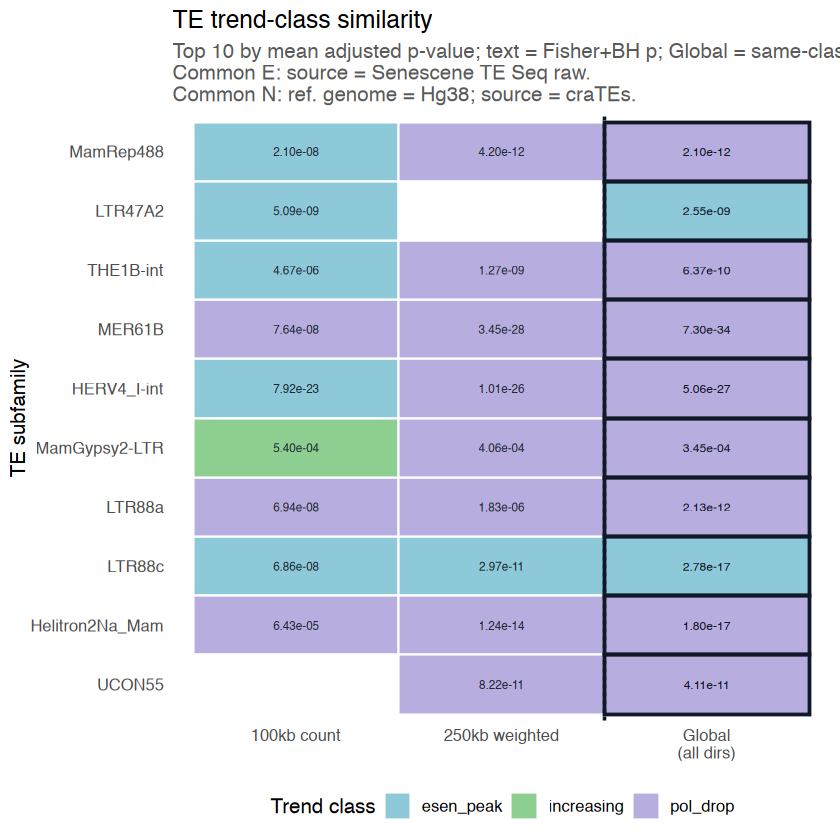

In [92]:
# ── TE trend-class similarity ───────────────────────────
te_classification_plot <- plot_te_classification_similarity(
  comparison_results,
  selected_te_space = selected_te_space,
  target_tes = analysis_tes,
  top_k = te_contrast_top_k,
  p_score_mode = te_p_score_mode,
  alpha = te_p_alpha,
  comparison_class = comparison_class
)
if (inherits(te_classification_plot, "ggplot")) {
  print(te_classification_plot)
}


### -- 4.2b - Activity-Score vs Contrast-Aggregated Class --

This is a small sanity check next to plot 4.2. `activity_score_class` is the class from the canonical TE-Seq trend logic in `scripts/te_trend_classification_f.R`. `contrast_aggregated_class` uses the same class vocabulary, but is inferred only from pairwise contrast directions plus aggregated raw p-values. So agreement means the global activity-shape call is also supported by the individual 2-way contrasts; disagreement marks TEs where the mean activity profile and the contrast-level evidence are telling slightly different stories.

In [93]:
# -- Activity-score class vs contrast-aggregated class -------
activity_vs_contrast_class_summary <- summarise_activity_vs_contrast_classification(te_padj_evidence)
print(activity_vs_contrast_class_summary, row.names = FALSE)

activity_vs_contrast_class_examples <- activity_vs_contrast_classification_examples(
  te_padj_evidence,
  max_rows = 12L)
print(activity_vs_contrast_class_examples, row.names = FALSE)


   result_label n_te_subfamilies n_matching_classes fraction_matching
    100kb count               10                  5               0.5
 250kb weighted               10                  8               0.8
 n_activity_score_non_noise n_contrast_aggregated_non_noise
                          9                              10
                          9                              10
 n_both_non_noise_matching n_both_non_noise_discordant
                         5                           4
                         8                           1
   result_label  te_subfamily activity_score_class contrast_aggregated_class
    100kb count   HERV4_I-int            esen_peak                  pol_drop
    100kb count     MamRep488            esen_peak                  pol_drop
    100kb count MamGypsy2-LTR           increasing                  pol_drop
 250kb weighted        LTR88a             pol_drop                 esen_peak
    100kb count     THE1B-int            esen_peak          

### ── 4.3 - Adjusted P-Value Evidence Range ──

Points show each result directory's aggregated adjusted p-value evidence per TE subfamily; the grey segment shows the range across result directories, and the label at the right is the maximum cross-result delta. With the default `mean_padj` mode, smaller x-values indicate stronger adjusted-p evidence.

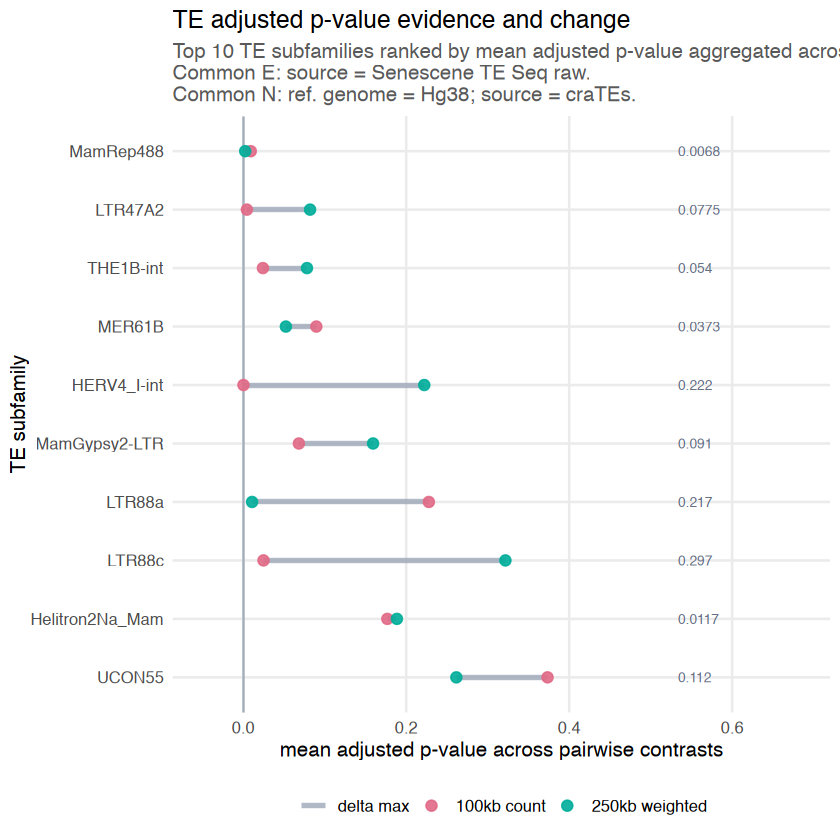

In [94]:
# ── Aggregated adjusted p-value evidence and change ─────
te_padj_evidence_plot <- plot_te_padj_evidence_change(
  comparison_results,
  selected_te_space = selected_te_space,
  target_tes = analysis_tes,
  top_k = te_contrast_top_k,
  p_score_mode = te_p_score_mode,
  alpha = te_p_alpha,
  comparison_class = comparison_class
)
if (inherits(te_padj_evidence_plot, "ggplot")) {
  print(te_padj_evidence_plot)
}


## 5 · Target gene matrix comparison

Target gene matrices are compared only when matching `target_gene_matrix_*.tsv` files exist across all selected result directories. The TE dimension starts from the same global TE frame as the activity and contrast sections; the gene dimension is then selected separately by target-matrix signal. `target_summary.tsv` is optional context.

### 5.1 - Target-matrix similarity

> Are Target-score-patterns and rankings similar across conditions and serval result directories?

Each stored contrast-specific target matrix is compared as one focused `gene x TE` vector using the same global `top_k` setting as the target-matrix frame.

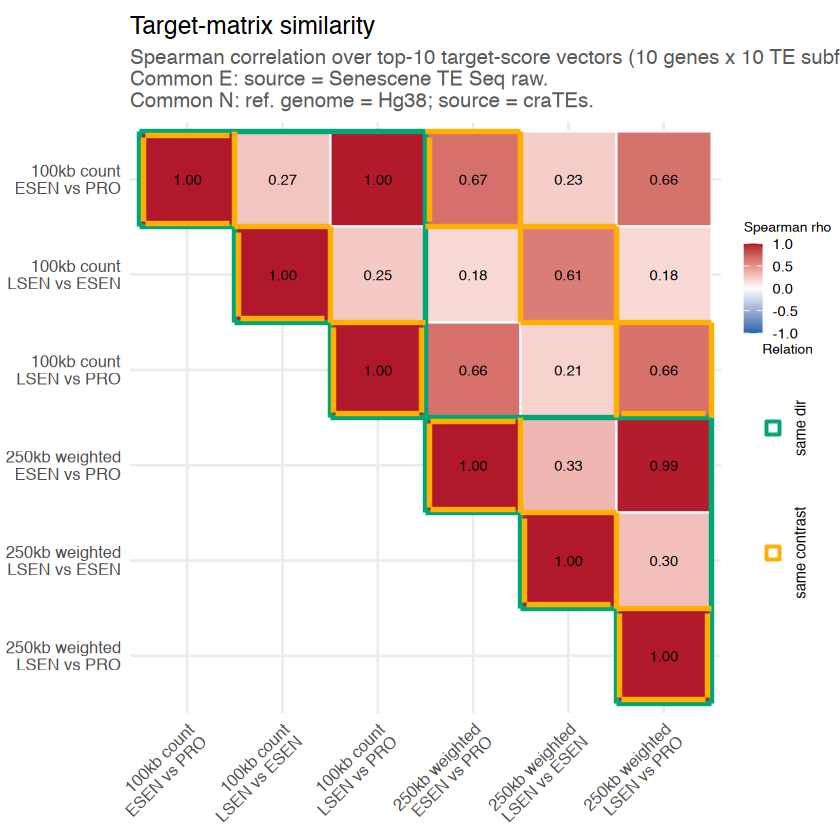

In [95]:
# ── Target matrix similarity across result dirs and contrasts ─────
# Uses stored target_gene_matrix_*.tsv objects; does not rerun getTargetMatrix().
source_project_file("scripts", "comparison_f.R")

target_matrix_similarity <- summarise_target_matrix_similarity(
  comparison_results,
  target_tes = analysis_tes,
  target_genes = target_genes,
  top_k = te_contrast_top_k,
  highlight_TEs = c("LTR5_Hs", "LTR5A", "LTR5B"),
  method = "spearman",
  comparison_class = comparison_class
)

target_matrix_similarity_genes <- target_genes
target_matrix_similarity_tes <- analysis_tes
if (identical(target_matrix_similarity$status, "ok")) {
  target_matrix_similarity_genes <- target_matrix_similarity$shared_genes
  target_matrix_similarity_tes <- target_matrix_similarity$shared_te_subfamilies
  target_matrix_similarity_plot <- plot_target_matrix_similarity(
    target_matrix_similarity,
    triangle = "upper"
  )
  target_matrix_similarity_plot
} else {
  message(target_matrix_similarity$reason)
}


### 5.2 - Target-matrix Jaccard similarity

Die Jaccard-Analyse verwendet denselben Gen- und TE-Rahmen wie die Spearman-Analyse in 5.1, fragt aber eine andere Sache: nicht, ob die kontinuierlichen Target-Scores ähnlich gerankt sind, sondern ob dieselben biologischen Features im Vergleich denselben Zustand bekommen. Mit `target_matrix_jaccard_sign_sensitive <- TRUE` und `target_matrix_jaccard_include_zero_state <- TRUE` werden Target-Scores explizit als drei getrennte Zustände behandelt: `positive` (`score > threshold`), `zero` (`abs(score) <= threshold`) und `negative` (`score < -threshold`). Dadurch zählt ein positiver Gene-TE-Link nicht als derselbe Befund wie ein negativer oder neutraler Link.

Warum Jaccard hier sinnvoll ist: Die Target-Matrix-Frage ist kategorialer als die Spearman-Frage. Spearman fragt, ob die kontinuierlichen Scores ähnlich gerankt sind; Jaccard fragt, ob dieselben TE-, Gen- oder Gene-TE-Features denselben Zustands-Call teilen. Das passt gut zu Target-Matrizen, weil biologisch oft wichtiger ist, ob ein Link reproduzierbar `positive`, `zero` oder `negative` ist, als ob alle kleinen Score-Unterschiede exakt gleich skaliert sind. Die Drei-Zustands-Variante zählt gemeinsame `zero`-Calls bewusst als Übereinstimmung; deshalb sollte sie auf dem fokussierten Gen/TE-Frame aus 5.1 interpretiert werden. Wenn ein voller, sehr dünn besetzter Frame analysiert wird und gemeinsame Nullen zu stark dominieren, kann `target_matrix_jaccard_include_zero_state <- FALSE` genutzt werden; dann bleiben Nullwerte als Abwesenheit eines aktiven Links berücksichtigt, ohne gemeinsame Null-Null-Paare zu belohnen.

Die drei Matrizen haben unterschiedliche biologische Auflösung:

- **TE-subfamily Jaccard**: Vergleicht, ob dieselben TE-Subfamilien überhaupt ein positives, neutrales oder negatives Target-Signal tragen. Biologisch fragt das: Werden dieselben TE-Familien als potenziell regulatorisch relevant für den Kontrast gesehen?
- **Gene Jaccard**: Vergleicht, ob dieselben Gene von TE-assoziierten Signalen betroffen sind, unabhängig davon, welche TE-Subfamilie den Beitrag liefert. Biologisch fragt das: Treffen die Resultate dieselben Zielgene oder Genprogramme?
- **Gene-TE-link Jaccard**: Vergleicht die konkreten `Gene x TE`-Beziehungen inklusive Richtung (`positive`, `zero`, `negative`). Biologisch ist das die strengste Ansicht: Sie fragt, ob derselbe TE dieselben Gene in dieselbe Richtung beeinflusst oder ob ein Link in einem Resultat aktiv, im anderen neutral bzw. entgegengesetzt ist.

> Are the same Gene TE-Links made (aktive/non-zero)? 

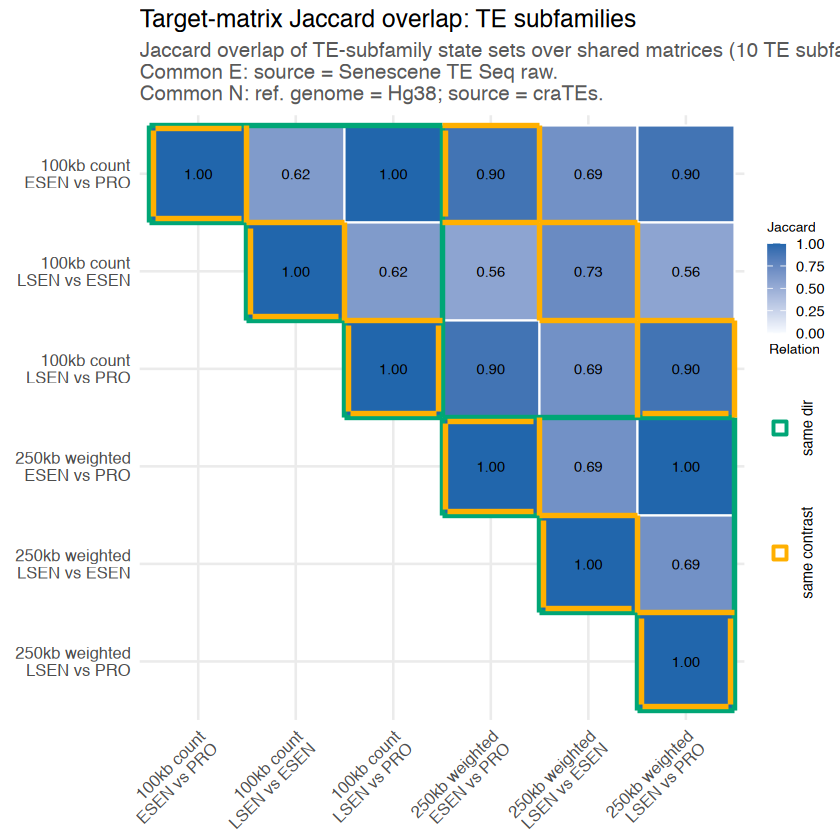

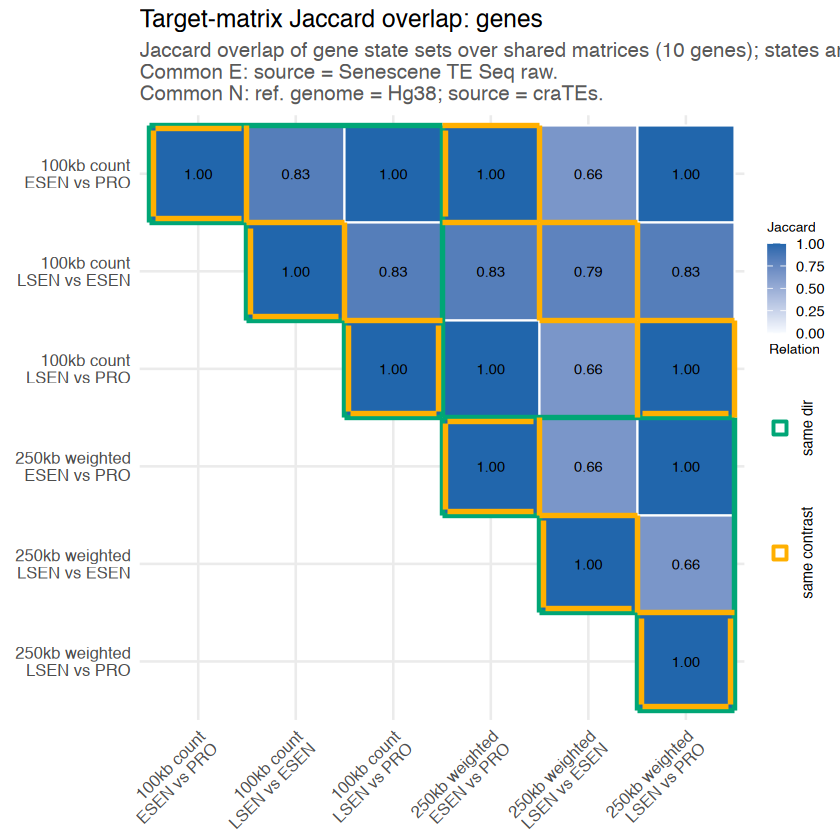

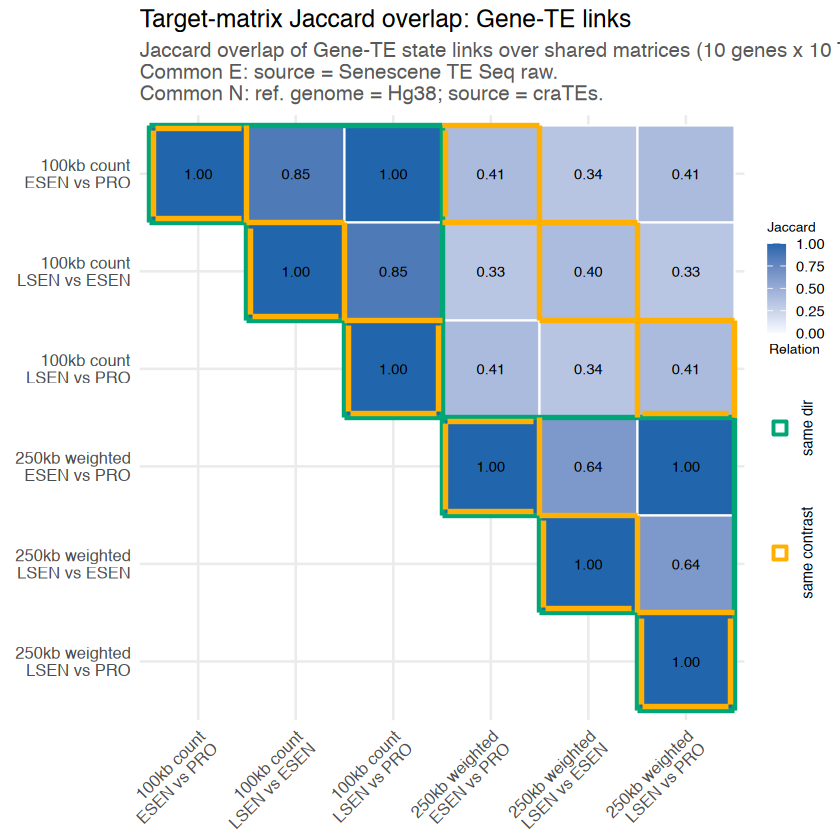

In [96]:
# ── Target matrix Jaccard overlap across result dirs and contrasts ─
# Uses stored target_gene_matrix_*.tsv objects; does not rerun getTargetMatrix().
target_matrix_jaccard_genes <- if (exists("target_matrix_similarity_genes")) target_matrix_similarity_genes else target_genes
target_matrix_jaccard_tes <- if (exists("target_matrix_similarity_tes")) target_matrix_similarity_tes else analysis_tes
target_matrix_jaccard_top_k <- if (exists("target_matrix_similarity") && identical(target_matrix_similarity$status, "ok")) NULL else te_contrast_top_k

target_matrix_jaccard_results <- list()
target_matrix_jaccard_plots <- list()

for (target_matrix_jaccard_level in target_matrix_jaccard_levels) {
  target_matrix_jaccard_results[[target_matrix_jaccard_level]] <- summarise_target_matrix_jaccard(
    comparison_results,
    target_tes = target_matrix_jaccard_tes,
    target_genes = target_matrix_jaccard_genes,
    top_k = target_matrix_jaccard_top_k,
    highlight_TEs = c("LTR5_Hs", "LTR5A", "LTR5B"),
    threshold = target_matrix_jaccard_threshold,
    sign_sensitive = target_matrix_jaccard_sign_sensitive,
    include_zero_state = target_matrix_jaccard_include_zero_state,
    level = target_matrix_jaccard_level,
    comparison_class = comparison_class
  )

  target_matrix_jaccard_current <- target_matrix_jaccard_results[[target_matrix_jaccard_level]]
  if (identical(target_matrix_jaccard_current$status, "ok")) {
    target_matrix_jaccard_plots[[target_matrix_jaccard_level]] <- plot_target_matrix_jaccard(
      target_matrix_jaccard_current,
      triangle = "upper"
    )
    print(target_matrix_jaccard_plots[[target_matrix_jaccard_level]])
  } else {
    message(target_matrix_jaccard_level, ": ", target_matrix_jaccard_current$reason)
  }
}

target_matrix_jaccard_te <- target_matrix_jaccard_results[["te_subfamily"]]
target_matrix_jaccard_gene <- target_matrix_jaccard_results[["gene"]]
target_matrix_jaccard_interaction <- target_matrix_jaccard_results[["gene_te_link"]]
target_matrix_jaccard <- target_matrix_jaccard_interaction
target_matrix_jaccard_plot <- target_matrix_jaccard_plots[["gene_te_link"]]


Saved: figures/target_matrix_comparison_top_10.pdf



Target matrix frame: 10 genes x 10 TE subfamilies across 2 result dirs and 3 target matrices.


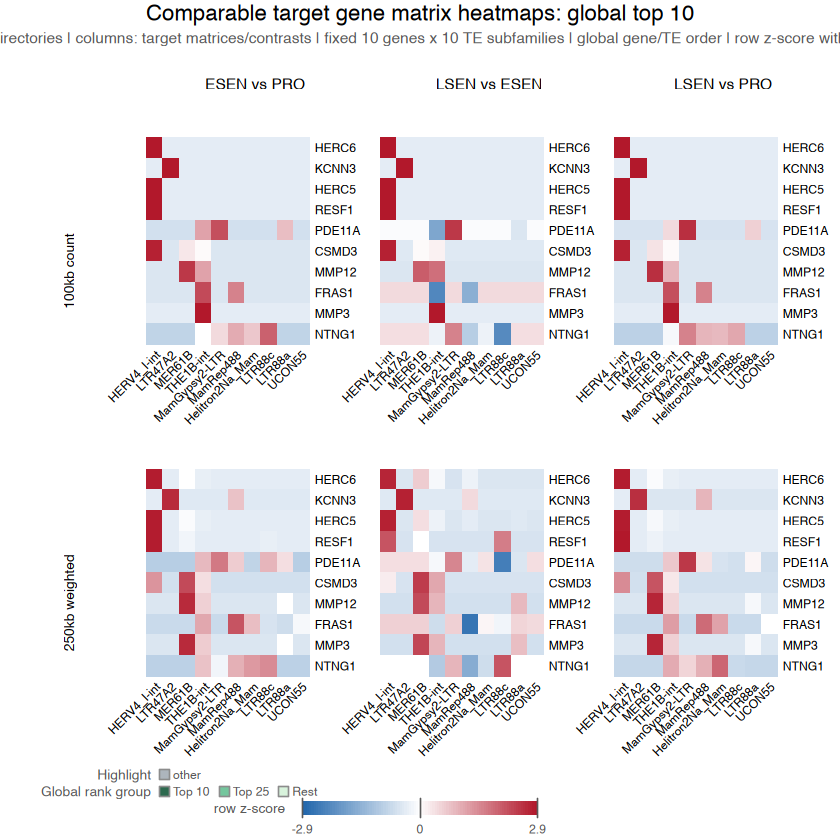

In [97]:
# ── Comparable target gene matrix frame ───────────────────
# Uses stored target_gene_matrix_*.tsv objects; does not rerun getTargetMatrix().
target_matrix_frame_genes <- if (exists("target_matrix_similarity_genes")) target_matrix_similarity_genes else target_genes
target_matrix_frame_tes <- if (exists("target_matrix_similarity_tes")) target_matrix_similarity_tes else analysis_tes

target_matrix_frame <- plot_target_matrix_full_frame(
  comparison_results,
  top_k = te_contrast_top_k,
  target_tes = target_matrix_frame_tes,
  target_genes = target_matrix_frame_genes,
  highlight_TEs = c("LTR5_Hs", "LTR5A", "LTR5B"),
  gene_label = "symbol",
  comparison_class = comparison_class,
  out_file = file.path("figures", sprintf("target_matrix_comparison_top_%s.pdf", te_contrast_top_k)),
  show = TRUE
)

if (identical(target_matrix_frame$status, "ok")) {
  cat(sprintf(
    "Target matrix frame: %d genes x %d TE subfamilies across %d result dirs and %d target matrices.\n",
    length(target_matrix_frame$selected_genes),
    length(target_matrix_frame$selected_tes),
    length(comparison_results),
    length(target_matrix_frame$common_target_matrices)
  ))
}

# Optional slow diagnostics: materialises the full shared gene x TE x result x contrast table.
run_full_target_support <- FALSE
if (isTRUE(run_full_target_support)) {
  target_gene_summary <- summarise_target_gene_matrices(
    comparison_results,
    target_tes = target_matrix_frame_tes,
    target_genes = target_matrix_frame_genes
  )

  if (identical(target_gene_summary$status, "ok")) {
    print(head(target_gene_summary$support_summary, 30), row.names = FALSE)
    print(plot_target_gene_support_overlap(
      comparison_results,
      target_tes = target_matrix_frame_tes,
      target_genes = target_matrix_frame_genes,
      target_summary = target_gene_summary
    ))
    print(plot_target_gene_matrix_heatmap(
      comparison_results,
      target_tes = target_matrix_frame_tes,
      target_genes = target_matrix_frame_genes,
      target_summary = target_gene_summary
    ))
  } else {
    message(target_gene_summary$reason)
  }
}

spearment correlation in between result dirs and conditions of target gene overlepa pro TE Contrast. 

## 6 · Final comparison summary

This final section collects the fixed-contrast evidence and the compact result-level comparison table.

### ── 6.1 - Fixed Contrast TE Evidence ──

`activity_contrast_focus_contrasts` can restrict the shown shared `padj_*`/`delta_*` contrasts; by default all available pairwise contrasts are printed. Question: which TEs show the strongest repeated evidence across result dirs in each contrast?

Rows use Fisher-aggregated adjusted p-values. Each panel is a compact summary of endpoint activity, signed distance, and aggregated p-value. TE-label fill marks non-noisy global trend classes from section 4.2; noisy/global-flat TEs stay unfilled. A label outline marks TEs that are significant in the selected fixed contrast.

The signed-distance panel/table is the contrast-specific activity delta: `mean_activity(condition A) - mean_activity(condition B)`. Positive values point toward condition A, negative values toward condition B; the grey interval shows how far the result directories differ for the same TE.

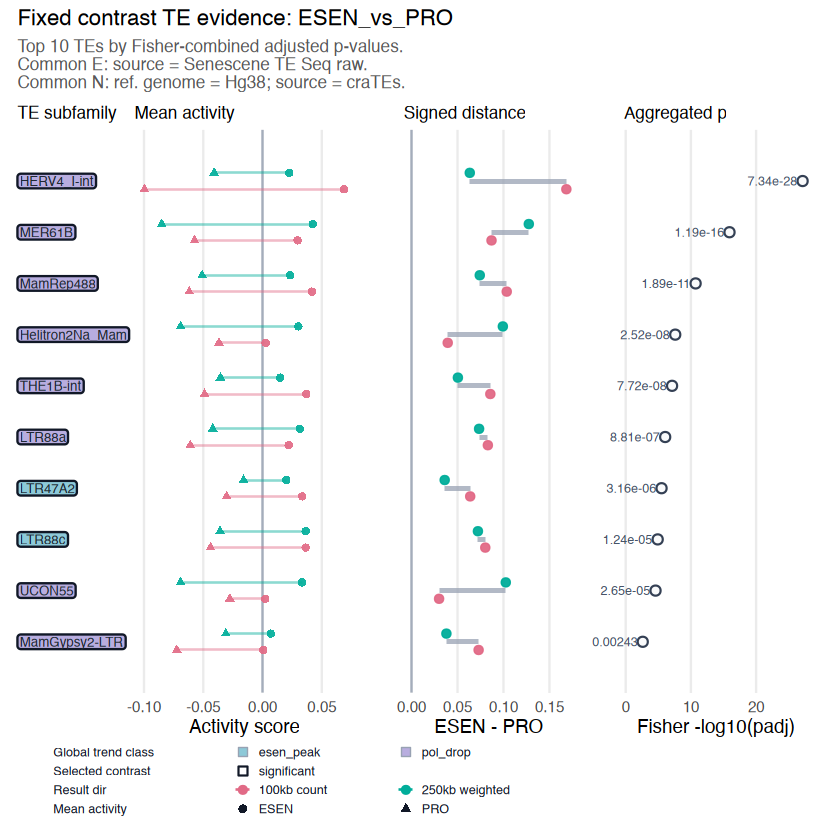

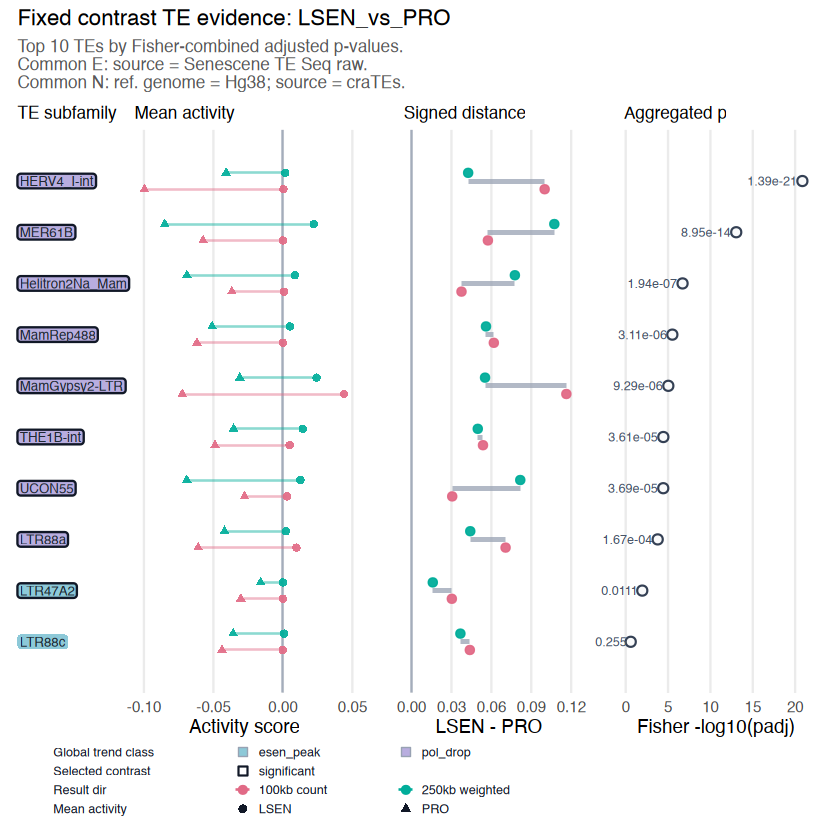

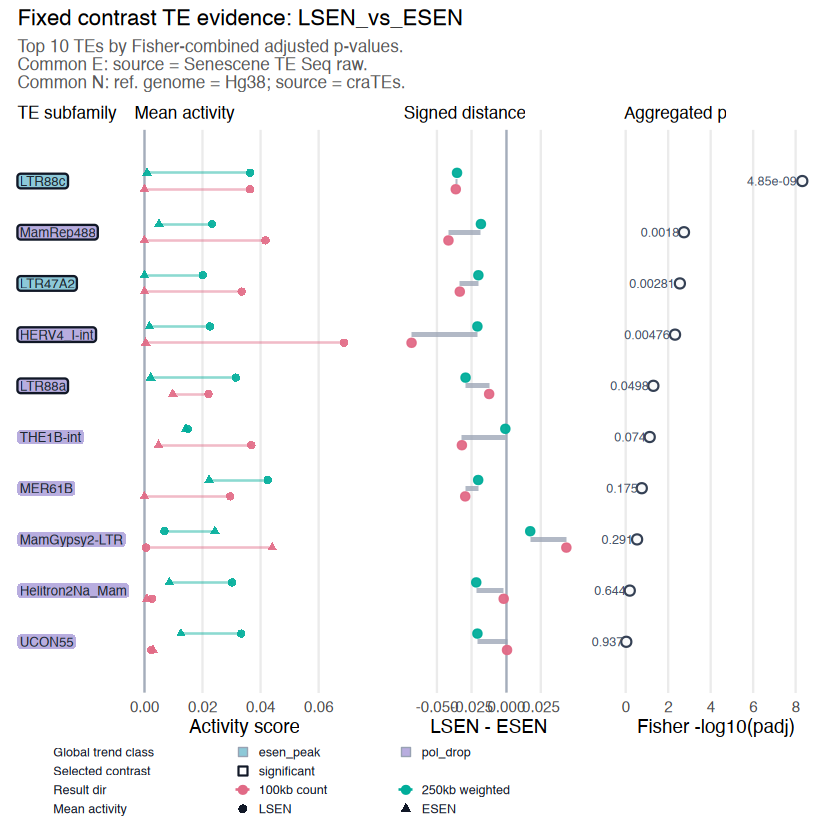

In [98]:
# ── Fixed-contrast top TE evidence across result dirs ────
source_project_file("scripts", "comparison_f.R")

if (!exists("comparison_class", inherits = TRUE)) {
  comparison_class <- classify_comparison_set(comparison_results)
}
if (!exists("selected_te_space", inherits = TRUE)) {
  selected_te_space <- NULL
}
if (!exists("analysis_tes", inherits = TRUE)) {
  analysis_tes <- NULL
}

if (!exists("activity_contrast_focus_contrasts", inherits = TRUE)) {
  activity_contrast_focus_contrasts <- NULL
}
if (!exists("activity_contrast_focus_top_k", inherits = TRUE)) {
  activity_contrast_focus_top_k <- if (exists("te_contrast_top_k", inherits = TRUE)) min(te_contrast_top_k, 12L) else 12L
}
if (!exists("activity_contrast_focus_alpha", inherits = TRUE)) {
  activity_contrast_focus_alpha <- if (exists("te_p_alpha", inherits = TRUE)) te_p_alpha else 0.05
}

activity_contrast_focus_summaries <- summarise_fixed_contrast_te_evidence_all(
  comparison_results,
  contrast_ids = activity_contrast_focus_contrasts,
  selected_te_space = selected_te_space,
  target_tes = analysis_tes,
  top_k = activity_contrast_focus_top_k,
  alpha = activity_contrast_focus_alpha,
  comparison_class = comparison_class
)

if (identical(activity_contrast_focus_summaries$status, "ok")) {
  activity_contrast_focus_summary <- activity_contrast_focus_summaries$summaries[[1]]
  activity_contrast_focus_plots <- print_fixed_contrast_te_evidence_plots(activity_contrast_focus_summaries)
} else {
  message(activity_contrast_focus_summaries$reason)
}


### ── 6.2 - Fixed-Contrast Summary Tables ──

These tables use the same top-k rows as the fixed-contrast plots and are printed for each pairwise contrast. The first table shows assigned classes per result directory and the majority class; the second table lists signed activity deltas; the third table lists each result directory's adjusted p-value together with the Fisher-aggregated p-value.

In [99]:
# ── Fixed-contrast class, signed-distance, and p-value tables ────
activity_contrast_tables <- list()
if (exists("activity_contrast_focus_summaries") && identical(activity_contrast_focus_summaries$status, "ok")) {
  for (contrast_id in activity_contrast_focus_summaries$contrasts) {
    fixed_contrast_summary <- activity_contrast_focus_summaries$summaries[[contrast_id]]
    activity_contrast_tables[[contrast_id]] <- list(
      class = print_fixed_contrast_class_table(fixed_contrast_summary),
      signed_distance = print_fixed_contrast_delta_table(fixed_contrast_summary),
      pvalue = print_fixed_contrast_pvalue_table(fixed_contrast_summary)
    )
  }
}


TE subfamily,TE marker,100kb count,250kb weighted,majority class,class votes,non-noise dirs
HERV4_I-int,not majority noise,ESEN higher,ESEN higher,ESEN higher,2,2/2
MER61B,not majority noise,ESEN higher,ESEN higher,ESEN higher,2,2/2
MamRep488,not majority noise,ESEN higher,ESEN higher,ESEN higher,2,2/2
Helitron2Na_Mam,not majority noise,ESEN higher,ESEN higher,ESEN higher,2,2/2
THE1B-int,not majority noise,ESEN higher,ESEN higher,ESEN higher,2,2/2
LTR88a,not majority noise,ESEN higher,ESEN higher,ESEN higher,2,2/2
LTR47A2,not majority noise,ESEN higher,ESEN higher,ESEN higher,2,2/2
LTR88c,not majority noise,ESEN higher,ESEN higher,ESEN higher,2,2/2
UCON55,not majority noise,flat_or_noisy,ESEN higher,mixed,1,1/2
MamGypsy2-LTR,not majority noise,ESEN higher,flat_or_noisy,mixed,1,1/2


TE subfamily,100kb count,250kb weighted,mean signed distance,min signed distance,max signed distance,significant dirs
HERV4_I-int,0.168,0.0633,0.116,0.0633,0.168,2/2
MER61B,0.087,0.128,0.107,0.087,0.128,2/2
MamRep488,0.104,0.0742,0.0889,0.0742,0.104,2/2
Helitron2Na_Mam,0.0393,0.0993,0.0693,0.0393,0.0993,2/2
THE1B-int,0.0857,0.0504,0.068,0.0504,0.0857,2/2
LTR88a,0.083,0.0735,0.0782,0.0735,0.083,2/2
LTR47A2,0.0638,0.036,0.0499,0.036,0.0638,2/2
LTR88c,0.0802,0.0722,0.0762,0.0722,0.0802,2/2
UCON55,0.03,0.102,0.0662,0.03,0.102,1/2
MamGypsy2-LTR,0.0729,0.0379,0.0554,0.0379,0.0729,1/2


TE subfamily,100kb count,250kb weighted,Fisher aggregated padj,mean padj,min padj,p-value dirs
HERV4_I-int,8.38e-18,1.29e-12,7.34e-28,6.47e-13,8.38e-18,2
MER61B,1.73e-04,1.67e-14,1.19e-16,8.66e-05,1.67e-14,2
MamRep488,6.13e-06,1.06e-07,1.89e-11,3.12e-06,1.06e-07,2
Helitron2Na_Mam,0.0062,1.89e-07,2.52e-08,0.0031,1.89e-07,2
THE1B-int,2.67e-04,1.42e-05,7.72e-08,1.41e-04,1.42e-05,2
LTR88a,3.51e-04,1.41e-04,8.81e-07,2.46e-04,1.41e-04,2
LTR47A2,1.61e-05,0.012,3.16e-06,0.00598,1.61e-05,2
LTR88c,2.67e-04,0.00309,1.24e-05,0.00168,2.67e-04,2
UCON55,0.119,1.57e-05,2.65e-05,0.0593,1.57e-05,2
MamGypsy2-LTR,0.00488,0.054,0.00243,0.0295,0.00488,2


TE subfamily,TE marker,100kb count,250kb weighted,majority class,class votes,non-noise dirs
HERV4_I-int,not majority noise,LSEN higher,LSEN higher,LSEN higher,2,2/2
MER61B,not majority noise,LSEN higher,LSEN higher,LSEN higher,2,2/2
Helitron2Na_Mam,not majority noise,LSEN higher,LSEN higher,LSEN higher,2,2/2
MamRep488,not majority noise,LSEN higher,LSEN higher,LSEN higher,2,2/2
MamGypsy2-LTR,not majority noise,LSEN higher,LSEN higher,LSEN higher,2,2/2
THE1B-int,not majority noise,LSEN higher,LSEN higher,LSEN higher,2,2/2
UCON55,not majority noise,flat_or_noisy,LSEN higher,mixed,1,1/2
LTR88a,not majority noise,LSEN higher,LSEN higher,LSEN higher,2,2/2
LTR47A2,not majority noise,LSEN higher,flat_or_noisy,mixed,1,1/2
LTR88c,majority noise,flat_or_noisy,flat_or_noisy,flat_or_noisy,2,0/2


TE subfamily,100kb count,250kb weighted,mean signed distance,min signed distance,max signed distance,significant dirs
HERV4_I-int,0.1,0.0426,0.0713,0.0426,0.1,2/2
MER61B,0.0574,0.107,0.0824,0.0574,0.107,2/2
Helitron2Na_Mam,0.0375,0.0777,0.0576,0.0375,0.0777,2/2
MamRep488,0.0619,0.056,0.0589,0.056,0.0619,2/2
MamGypsy2-LTR,0.116,0.0553,0.0858,0.0553,0.116,2/2
THE1B-int,0.0537,0.0498,0.0517,0.0498,0.0537,2/2
UCON55,0.0306,0.0817,0.0562,0.0306,0.0817,1/2
LTR88a,0.0707,0.0441,0.0574,0.0441,0.0707,2/2
LTR47A2,0.0303,0.016,0.0231,0.016,0.0303,1/2
LTR88c,0.0438,0.0367,0.0403,0.0367,0.0438,0/2


TE subfamily,100kb count,250kb weighted,Fisher aggregated padj,mean padj,min padj,p-value dirs
HERV4_I-int,2.72e-11,9.61e-13,1.39e-21,1.41e-11,9.61e-13,2
MER61B,0.0018,1.43e-12,8.95e-14,9.02e-04,1.43e-12,2
Helitron2Na_Mam,0.0195,5.12e-07,1.94e-07,0.00974,5.12e-07,2
MamRep488,0.00129,1.46e-04,3.11e-06,7.20e-04,1.46e-04,2
MamGypsy2-LTR,8.75e-05,0.00693,9.29e-06,0.00351,8.75e-05,2
THE1B-int,0.0122,2.13e-04,3.61e-05,0.00623,2.13e-04,2
UCON55,0.152,1.76e-05,3.69e-05,0.0759,1.76e-05,2
LTR88a,6.95e-04,0.0197,1.67e-04,0.0102,6.95e-04,2
LTR47A2,0.00979,0.15,0.0111,0.08,0.00979,2
LTR88c,0.0723,0.962,0.255,0.517,0.0723,2


TE subfamily,TE marker,100kb count,250kb weighted,majority class,class votes,non-noise dirs
LTR88c,not majority noise,ESEN higher,ESEN higher,ESEN higher,2,2/2
MamRep488,not majority noise,ESEN higher,ESEN higher,ESEN higher,2,2/2
LTR47A2,not majority noise,ESEN higher,flat_or_noisy,mixed,1,1/2
HERV4_I-int,not majority noise,ESEN higher,flat_or_noisy,mixed,1,1/2
LTR88a,not majority noise,flat_or_noisy,ESEN higher,mixed,1,1/2
THE1B-int,majority noise,flat_or_noisy,flat_or_noisy,flat_or_noisy,2,0/2
MER61B,majority noise,flat_or_noisy,flat_or_noisy,flat_or_noisy,2,0/2
MamGypsy2-LTR,majority noise,flat_or_noisy,flat_or_noisy,flat_or_noisy,2,0/2
Helitron2Na_Mam,majority noise,flat_or_noisy,flat_or_noisy,flat_or_noisy,2,0/2
UCON55,majority noise,flat_or_noisy,flat_or_noisy,flat_or_noisy,2,0/2


TE subfamily,100kb count,250kb weighted,mean signed distance,min signed distance,max signed distance,significant dirs
LTR88c,-0.0364,-0.0355,-0.0359,-0.0364,-0.0355,2/2
MamRep488,-0.0417,-0.0182,-0.03,-0.0417,-0.0182,2/2
LTR47A2,-0.0335,-0.0201,-0.0268,-0.0335,-0.0201,1/2
HERV4_I-int,-0.0683,-0.0208,-0.0445,-0.0683,-0.0208,1/2
LTR88a,-0.0123,-0.0293,-0.0208,-0.0293,-0.0123,1/2
THE1B-int,-0.032,-0.000615,-0.0163,-0.032,-0.000615,0/2
MER61B,-0.0296,-0.0202,-0.0249,-0.0296,-0.0202,0/2
MamGypsy2-LTR,0.0434,0.0174,0.0304,0.0174,0.0434,0/2
Helitron2Na_Mam,-0.00179,-0.0216,-0.0117,-0.0216,-0.00179,0/2
UCON55,0.000619,-0.0208,-0.0101,-0.0208,0.000619,0/2


TE subfamily,100kb count,250kb weighted,Fisher aggregated padj,mean padj,min padj,p-value dirs
LTR88c,0.00208,1.00e-07,4.85e-09,0.00104,1.00e-07,2
MamRep488,0.0264,0.00714,0.0018,0.0168,0.00714,2
LTR47A2,0.0037,0.0838,0.00281,0.0438,0.0037,2
HERV4_I-int,8.41e-04,0.666,0.00476,0.334,8.41e-04,2
LTR88a,0.682,0.0127,0.0498,0.347,0.0127,2
THE1B-int,0.06,0.234,0.074,0.147,0.06,2
MER61B,0.267,0.157,0.175,0.212,0.157,2
MamGypsy2-LTR,0.2,0.417,0.291,0.308,0.2,2
Helitron2Na_Mam,0.505,0.566,0.644,0.535,0.505,2
UCON55,0.85,0.784,0.937,0.817,0.784,2


In [100]:
# ── Compact final comparison table ───────────────────────
final_comparison_summary <- summarise_comparison_final(comparison_results)
print(final_comparison_summary, row.names = FALSE)

                                            result_id    comparison_class
   results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs same E, different N
 results_E_Senescene_TE_Seq_raw_N_w_2.5e5_Hg38_craTEs same E, different N
    mean_r2 mean_r2_ratio mean_sparsity_percent activity_zero_fraction
 0.09367642     0.6780923              73.38569              0.7338569
 0.12715656     0.6782676              68.45716              0.6845716
                       lambda_best_summary n_significant_te_subfamilies
 sample median=0.0851078; global=0.0934057                          324
                   sample median=0.0660243                          506
 target_gene_support_summary warnings_or_skipped_blocks
                   available                           
                   available                           
